# DeFi EDA: Aave

## Introduction

Aave — протокол кредитования; Годовой период: 01.11.2025–31.10.2026; котировки: 21.11.2025–31.10.2026.

Критерий топ-50 подтверждён на этапе выбора 20.11.2026 по таблице DeFiLlama: Aave занимал вторую позицию;

**Самостоятельный запуск:** Python 3.11+; `pip install pandas numpy matplotlib seaborn ipython`. Для Jupyter: `pip install jupyterlab ipykernel`. Run All запускается без `src/`, `.env` и файлов проекта.

## Data Sources

Пять инструментов использованы для реальных данных: 
DeFiLlama — TVL/fees/revenue; 
CoinGecko — цены, капитализация и объёмы; 
The Graph — резервы и история параметров; 
web3.py — RPC-логи и исторические contract calls; 
Etherscan API V2 — независимая выгрузка тех же логов. 
Встроенный gzip-блок содержит входные таблицы и нормализованные реальные события, выбранные raw Graph records, а также исходные RPC calldata/ответы независимой проверки.
SHA-256 проверяет целостность встроенного блока;

In [1]:
import base64, gzip, hashlib, json, io
from pathlib import Path
from decimal import Decimal
from datetime import timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown, Image
EDA_DIR = Path.cwd() / "eda_output"
OUT = EDA_DIR / "review"
OUT.mkdir(parents=True, exist_ok=True)
POOL = '0x87870Bca3F3fD6335C3F4ce8392D69350B4fA4E2'
RESERVES = {'USDC': ('0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48', 6), 'WETH': ('0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2', 18), 'USDT': ('0xdac17f958d2ee523a2206206994597c13d831ec7', 6)}

Matplotlib is building the font cache; this may take a moment.


In [2]:
SNAPSHOT_B64 = '...'
compressed=base64.b64decode(SNAPSHOT_B64)
assert hashlib.sha256(compressed).hexdigest()=='4eb4a919e4225740aa452f09306ed234972b88cdcb8554d654a32cc7d9edad17'
data=json.loads(gzip.decompress(compressed))
display(pd.DataFrame(data["provenance"]))

,source,url,fetched_at_utc,original_cache_sha256
0,DeFiLlama,https://api.llama.fi/protocol/aave,2026-11-20T18:44:13.253072+00:00,47344c6affdfcd886a6f952f28697ac74d20245da2d1dc...
1,CoinGecko,https://api.coingecko.com/api/v3/coins/aave/ma...,2026-11-20T18:44:19.393435+00:00,8a4e43432590b9e5124c1fa88723f71fa6250f6ffc20a7...
2,DeFiLlama fees,https://api.llama.fi/summary/fees/aave,2026-11-20T20:03:58.700139+00:00,d89560cced37b0eb1965a20b530153a2d79e935c8bd6e0...
3,The Graph,https://gateway.thegraph.com/api/subgraphs/id/...,2026-11-20T19:14:26.516445+00:00,78e2be444917cb293acca8064149f056d28aab15b1deeb...
4,Etherscan V2,https://api.etherscan.io/v2/api,2026-11-20T19:12:27.331800+00:00,cd0f1ceeffee70ba41e8563854227ebb28c6f36e9d7ade...
5,web3.py,https://eth.drpc.org,2026-11-20T19:09:30.865667+00:00,d73f86b459ea536c15155ba27ef25d9a1d37195d49e90e...
6,USDC historical RPC,https://eth.drpc.org,2026-11-21T08:22:35.877721+00:00,2d42e61a85f5a03e5d0ad4b814ae35f39391033b8c2ce7...


## Data Processing

In [3]:
def safe_ratio(numerator, denominator):
    return numerator / denominator.where(denominator > 0)


def log_returns(series):
    """Do not bridge missing dates or turn non-positive levels into returns."""
    return np.log(series.where(series > 0)).diff()


def annualized_volatility(returns, periods_per_year=365):
    """Sample standard deviation of observed daily returns, annualized."""
    if periods_per_year <= 0:
        raise ValueError("Annualization frequency must be positive")
    return float(returns.std(ddof=1) * np.sqrt(periods_per_year))


def ray_to_apy(value):
    """Official Aave frontend convention: APR in ray, per-second compounding."""
    apr = float(Decimal(str(value)) / Decimal(10**27))
    if not np.isfinite(apr) or apr < 0:
        raise ValueError("Invalid ray APR")
    return float(np.expm1(31536000 * np.log1p(apr / 31536000)))


def lending_snapshot(records):
    rows = []
    for symbol, (asset, decimals) in RESERVES.items():
        matches = [r for r in records if r["underlyingAsset"].lower() == asset and (r["pool"].get("pool") or "").lower() == POOL.lower()]
        if len(matches) != 1:
            raise ValueError(f"Expected one verified reserve: {symbol}")
        r = matches[0]
        if int(r["decimals"]) != decimals:
            raise ValueError(f"Unexpected decimals for {symbol}")
        unit = Decimal(10)**decimals
        amount = lambda key: float(Decimal(r[key]) / unit)
        stable = amount("totalPrincipalStableDebt")
        supply, variable, available = (amount(k) for k in ["totalATokenSupply", "totalCurrentVariableDebt", "availableLiquidity"])
        rows.append({"symbol": symbol, "asset": asset, "decimals": decimals,
            "last_update_utc": pd.to_datetime(r["lastUpdateTimestamp"], unit="s", utc=True),
            "supply_token": supply, "variable_borrow_token": variable, "stable_principal_token": stable,
            "borrow_token": variable if stable == 0 else np.nan,
            "available_token": available, "utilization_reported": float(r["utilizationRate"]),
            "borrow_supply_ratio": variable / supply if stable == 0 and supply > 0 else np.nan,
            "variable_debt_liquidity_ratio": variable / (variable+available) if variable+available > 0 else np.nan,
            "supply_apy": ray_to_apy(r["liquidityRate"]), "variable_borrow_apy": ray_to_apy(r["variableBorrowRate"])})
    return pd.DataFrame(rows).set_index("symbol")


def correlations(x, y):
    """Pairwise complete cases; symmetric 1/99% marginal trimming, no winsorization."""
    pair = pd.concat([x.rename('x'), y.rename('y')], axis=1).replace([np.inf, -np.inf], np.nan).dropna()
    low, high = pair.quantile(.01), pair.quantile(.99)
    kept = pair.loc[pair.ge(low).all(axis=1) & pair.le(high).all(axis=1)]
    def coefficient(frame, ranks=False):
        if len(frame)<3 or frame.nunique().min()<2:return np.nan
        if ranks:frame=frame.rank(method='average')
        return frame.x.corr(frame.y)
    return {'n': len(pair), 'pearson': coefficient(pair), 'spearman': coefficient(pair,True),
            'trim_n': len(kept), 'removed': len(pair)-len(kept), 'trim_pearson': coefficient(kept),
            'trim_spearman': coefficient(kept,True)}


def normalized(frame):
    if frame.iloc[0].isna().any() or (frame.iloc[0] <= 0).any():
        raise ValueError('A positive common initial base is required')
    return frame.div(frame.iloc[0])*100


def reserve_quality(frame):
    out=frame.copy()
    out['quality_invalid']=(out.available_token<0)|~out.utilization_reported.between(0,1)|(out.supply_token<0)|(out.borrow_token<0)
    out['utilization_valid']=out.utilization_reported.where(~out.quality_invalid)
    return out


In [4]:
def make_eda_plots(b):
    """Ten publication-size figures, using only actual cached observations."""
    import numpy as np
    import pandas as pd
    import seaborn as sns

    sns.set_theme(style="whitegrid", font="DejaVu Sans", palette="colorblind",
                  rc={"grid.alpha": .22, "axes.titlesize": 12, "axes.labelsize": 10})
    output = EDA_DIR / "figures"
    output.mkdir(parents=True, exist_ok=True)
    paths = {}
    p, t, e = b["protocol"], b["tokens"], b["economics"]

    def finish(fig, name, dated=()):
        for ax in dated:
            ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m", tz=timezone.utc))
            ax.set_xlabel("Дата (UTC)")
        fig.tight_layout()
        path = output / f"{name}.png"
        fig.savefig(path, dpi=220, bbox_inches="tight", facecolor="white")
        plt.close(fig)
        paths[name] = path

    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    (p.aave_tvl_usd/1e9).plot(ax=ax[0], color="#4472c4", lw=2)
    ax[0].set(title="Aave: TVL и изменения за 30/90 календарных дней", ylabel="TVL, млрд USD")
    (p[["tvl_change_30d", "tvl_change_90d"]]*100).rename(columns={"tvl_change_30d": "30 дней", "tvl_change_90d": "90 дней"}).plot(ax=ax[1])
    ax[1].axhline(0, color="gray", lw=.8)
    ax[1].set_ylabel("Изменение TVL, %")
    finish(fig, "01_tvl", ax)

    fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
    trio = p[["aave_tvl_usd", "morpho_tvl_usd", "compound_tvl_usd"]].rename(columns={"aave_tvl_usd": "Aave", "morpho_tvl_usd": "Morpho", "compound_tvl_usd": "Compound"})
    (trio/1e9).plot(ax=ax[0])
    ax[0].set(title="Сравнение родительских протоколов DeFiLlama", ylabel="TVL, млрд USD")
    (p.aave_share_three*100).plot(ax=ax[1], color="#4472c4")
    ax[1].set(ylabel="Доля Aave в TVL тройки, %", ylim=(0, 100))
    (trio/trio.iloc[0]*100).plot(ax=ax[2])
    ax[2].set(ylabel="TVL, база 100", title="Общая база: 01.11.2025 = 100")
    finish(fig, "02_competitors", ax)

    fig, ax = plt.subplots(figsize=(11, 6))
    shares = b["chain_latest"].share_parent_tvl.sort_values(ascending=False)
    top = shares.head(7).copy()
    if len(shares) > 7:
        top.loc["Остальные сети"] = shares.iloc[7:].sum()
    (top.sort_values()*100).plot.barh(ax=ax, color="#4472c4")
    for i, v in enumerate(top.sort_values()*100):
        ax.text(v+.6, i, f"{v:.2f}%", va="center", fontsize=9)
    ax.set(title="Распределение TVL Aave по сетям — 31.10.2026, 00:00 UTC", xlabel="Доля в TVL Aave, %", ylabel="Сеть", xlim=(0,100))
    finish(fig, "03_chains")

    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    (e[["fees_usd_ma7", "revenue_usd_ma7"]]/1e6).rename(columns={"fees_usd_ma7": "Fees", "revenue_usd_ma7": "Protocol revenue"}).plot(ax=ax[0])
    ax[0].set(title="Экономическая активность Aave — скользящее среднее за 7 дней", ylabel="Средний дневной поток, млн USD")
    (e[["fees_tvl_daily", "revenue_tvl_daily"]].rolling(7, min_periods=7).mean()*1e4).rename(columns={"fees_tvl_daily": "Fees / TVL", "revenue_tvl_daily": "Revenue / TVL"}).plot(ax=ax[1])
    ax[1].set_ylabel("Средний дневной поток / TVL, б.п.")
    if not e.fees_usd.notna().any():
        ax[0].text(.5,.5,"Fees/revenue недоступны; пропуски не заменены нулями",ha="center",transform=ax[0].transAxes)
    finish(fig, "04_economics", ax)

    fig, axes = plt.subplots(3, 3, figsize=(13, 9))
    for column, (symbol, row) in enumerate(b["lending"].iterrows()):
        scale = 1e6 if symbol != "WETH" else 1e3
        label = "млн "+symbol if symbol != "WETH" else "тыс. WETH"
        axes[0,column].bar(["Supply", "Borrow"], [row.supply_token/scale, row.borrow_token/scale], color=["#4472c4", "#d97732"])
        axes[0,column].set(title=symbol, ylabel=label)
        for i, v in enumerate([row.supply_token/scale, row.borrow_token/scale]):
            axes[0,column].text(i, v, f"{v:,.1f}", ha="center", va="bottom", fontsize=9)
        axes[0,column].margins(y=.2)
        axes[1,column].bar(["Subgraph", "Borrow/Supply"], [row.utilization_reported*100,row.borrow_supply_ratio*100], color=["#328770", "#7890a6"])
        axes[1,column].set(ylabel="Использование, %", ylim=(0,105))
        for i,v in enumerate([row.utilization_reported*100,row.borrow_supply_ratio*100]):
            axes[1,column].text(i,v,f"{v:.2f}%",ha="center",va="bottom",fontsize=9)
        axes[2,column].bar(["Supply", "Variable borrow"], [row.supply_apy*100,row.variable_borrow_apy*100], color=["#4472c4", "#d97732"])
        axes[2,column].set_ylabel("Расчётный APY, %")
    fig.suptitle("Lending snapshot Aave V3 Ethereum — блок 26316188, 31.10.2026\nБалансы в единицах каждого токена; APY при неизменном APR", fontsize=13)
    finish(fig, "05_lending_snapshot")

    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    t.aave_price_usd.plot(ax=ax[0],color="#4472c4")
    ax[0].set(title="Рыночная динамика AAVE и ETH — доступная история", ylabel="AAVE, USD")
    prices=t[["aave_price_usd","eth_price_usd"]].dropna()
    (prices/prices.iloc[0]*100).rename(columns={"aave_price_usd":"AAVE","eth_price_usd":"ETH"}).plot(ax=ax[1])
    ax[1].set_ylabel("Цена: первая общая дата = 100")
    finish(fig,"06_token_prices",ax)

    fig, ax = plt.subplots(3, 1, figsize=(11, 9))
    (t.aave_log_return*100).plot(ax=ax[0],color="#4472c4",lw=.9)
    ax[0].set(title="AAVE: дневные логарифмические доходности",ylabel="log(Pt/Pt−1), %")
    ax[1].hist(t.aave_log_return.dropna()*100,bins=35,color="#4472c4",alpha=.85)
    ax[1].set(xlabel="Дневная логарифмическая доходность, %",ylabel="Число дней",title="Распределение фактических дневных доходностей")
    (t.aave_rolling_30d_vol_annual*100).plot(ax=ax[2],color="#7c4d9a")
    ax[2].set(title="30-дневная реализованная волатильность, годовое приведение",ylabel="std(log r) × √365, %")
    finish(fig,"07_returns_volatility",[ax[0],ax[2]])

    fig, ax = plt.subplots(2, 1, figsize=(11, 7),sharex=True)
    cap_tvl=pd.DataFrame({"Market Cap AAVE":t.aave_market_cap_usd,"TVL Aave":p.aave_tvl_usd}).loc[t.aave_market_cap_usd.notna()]/1e9
    cap_tvl.plot(ax=ax[0],logy=True)
    ax[0].set(title="Капитализация AAVE и TVL Aave — совпадающие даты",ylabel="млрд USD, логарифмическая шкала")
    t.market_cap_tvl.plot(ax=ax[1],color="#7c4d9a")
    ax[1].set_ylabel("Market Cap / TVL, доля")
    finish(fig,"08_valuation",ax)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
    if len(b["joint"]):
        sns.heatmap(b["correlation_matrix"],vmin=-1,vmax=1,cmap="vlag",annot=True,fmt=".2f",ax=ax[0],square=True,cbar=False)
        ax[0].tick_params(axis="x",labelrotation=45,labelsize=8)
        ax[0].tick_params(axis="y",labelsize=8)
        ax[0].set_title(f"Pearson: дневные изменения, n={len(b['joint'])}")
        ax[1].scatter(b["joint"]["Δlog TVL"]*100,b["joint"]["AAVE r"]*100,s=14,alpha=.5,color="#4472c4")
    else:
        ax[0].text(.5,.5,"Недостаточно совместных наблюдений",ha="center",transform=ax[0].transAxes)
    ax[1].set(title="Изменение TVL и доходность AAVE",xlabel="Δlog TVL, %",ylabel="Логарифмическая доходность AAVE, %")
    finish(fig,"09_associations")

    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    counts=b["events"].event_name.value_counts().reindex(["Supply","Borrow","Repay"])
    counts.plot.bar(ax=ax[0,0],rot=0,color=["#4472c4","#d97732","#7c4d9a"])
    ax[0,0].set(title="Число событий по типам",xlabel="Тип события",ylabel="События")
    b["hourly"].plot.bar(stacked=True,ax=ax[0,1],width=.85,color=["#4472c4","#d97732","#7c4d9a"])
    ax[0,1].set(title="Распределение активности по часам",xlabel="Час UTC",ylabel="События")
    ax[0,1].set_ylim(0,b["hourly"].sum(axis=1).max()*1.35)
    ax[0,1].legend(title="События",loc="upper right",fontsize=9)
    ax[0,1].tick_params(axis="x",rotation=0,labelsize=8)
    b["participants"].plot.bar(ax=ax[1,0],rot=0,color="#328770")
    ax[1,0].set(title="Уникальные участники по типам операций",xlabel="Тип события",ylabel="Адреса, объединение ролей")
    b["reserve_counts"].head(8).sort_values().plot.barh(ax=ax[1,1],color="#7890a6")
    ax[1,1].set(title="Восемь резервов с наибольшим числом событий",xlabel="События",ylabel="Резерв")
    fig.suptitle("Однодневный on-chain case study — 31.10.2026 UTC, Aave V3 Ethereum",fontsize=13)
    finish(fig,"10_onchain_case")
    return paths

def plot_history(r):
    fig,axes=plt.subplots(3,2,figsize=(12,10),sharex=True)
    for i,s in enumerate(RESERVES):
        h=r['lending_daily'].query('symbol == @s').set_index('day')
        scale=1e6 if s!='WETH' else 1e3
        for column,label in [('supply_token','Supply'),('borrow_token','Borrow')]:
            axes[i,0].plot(h.index,h[column]/scale,label=label)
        axes[i,0].legend()
        axes[i,0].set(title=s,ylabel=('млн ' if s!='WETH' else 'тыс. ')+s)
        axes[i,1].plot(h.index,h.utilization_valid*100,color='#328770',marker='.',label='В пределах [0,100%]')
        bad=h.loc[h.quality_invalid]
        if len(bad):
            axes[i,1].scatter(bad.index,bad.utilization_reported*100,color='red',marker='x',label='Аномалия источника')
            axes[i,1].axhline(100,color='gray',linestyle=':')
            axes[i,1].legend(fontsize=8)
            axes[i,0].set_title(s+' — остатки subgraph, требуется сверка')
        axes[i,1].set(title=s+' — utilization subgraph',ylabel='%')
    fig.suptitle('02–31.10.2026: последние событийные наблюдения суток (UTC)')
    import matplotlib.dates as mdates
    for ax in axes.flat:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
        ax.set_xlabel('Дата UTC')
    fig.tight_layout(); path=OUT/'11_lending_30d.png'
    fig.savefig(path,dpi=220,bbox_inches='tight');plt.close(fig)
    return path


In [5]:

def read_table(name):
    frame = pd.read_csv(io.StringIO(data[name]), index_col=0)
    frame.index = pd.to_datetime(frame.index, utc=True)
    assert frame.index.is_unique and frame.index.is_monotonic_increasing
    assert len(frame) == 365
    return frame

p, t, e, chains = [read_table(name) for name in ['protocol','market','economics','chains']]
assert not p.isna().any().any() and not e.isna().any().any()
assert t.isna().sum().eq(20).all()
assert t.loc['2025-11-21':].notna().all().all()
p['tvl_change_30d'] = p.aave_tvl_usd.pct_change(30, fill_method=None)
p['tvl_change_90d'] = p.aave_tvl_usd.pct_change(90, fill_method=None)
trio = p[['aave_tvl_usd','morpho_tvl_usd','compound_tvl_usd']]
p['aave_share_three'] = p.aave_tvl_usd / trio.sum(axis=1, min_count=3)
p['tvl_log_change'] = log_returns(p.aave_tvl_usd)
for coin in ['aave','eth']:
    t[coin+'_log_return'] = log_returns(t[coin+'_price_usd'])
t['aave_rolling_30d_vol_annual'] = t.aave_log_return.rolling(30,min_periods=30).std(ddof=1)*np.sqrt(365)
t['market_cap_tvl'] = t.aave_market_cap_usd / p.aave_tvl_usd
for metric in ['fees','revenue']:
    e[metric+'_tvl_daily'] = e[metric+'_usd']/p.aave_tvl_usd
    e[metric+'_usd_ma7'] = e[metric+'_usd'].rolling(7,min_periods=7).mean()
chain_latest = chains.iloc[-1].dropna().sort_values(ascending=False).to_frame('tvl_usd')
chain_latest['share_parent_tvl'] = chain_latest.tvl_usd/p.aave_tvl_usd.iloc[-1]
lending = lending_snapshot(data['reserves'])
daily=[]
for item in data['daily_reserves']:
    frame=lending_snapshot(item['records']).reset_index()
    frame['day']=pd.Timestamp(item['day'],tz='UTC')
    daily.append(frame)
daily=reserve_quality(pd.concat(daily,ignore_index=True))
assert len(daily)==90 and not daily.duplicated(['day','symbol']).any()
assert daily.quality_invalid.sum()==25 and daily.stable_principal_token.eq(0).all()
events=pd.DataFrame(data['web3'])
other=pd.DataFrame(data['etherscan'])
key=['tx_hash','log_index']
assert not events.duplicated(key).any() and not other.duplicated(key).any()
pd.testing.assert_frame_equal(events.sort_values(key).reset_index(drop=True),other[events.columns].sort_values(key).reset_index(drop=True),check_dtype=False)
events['block_time']=pd.to_datetime(events.block_time,utc=True)
assert events.block_time.between(pd.Timestamp('2026-10-31',tz='UTC'),pd.Timestamp('2026-11-01',tz='UTC'),inclusive='left').all()
assert events.pool_address.str.lower().eq(POOL.lower()).all()
def participants(frame):
    return len({v.lower() for c in ['user','on_behalf_of','repayer'] for v in frame[c].dropna() if v and v!='0x'+'0'*40})
hourly=events.groupby([events.block_time.dt.hour,'event_name']).size().unstack(fill_value=0).reindex(index=range(24),columns=['Supply','Borrow','Repay'],fill_value=0)
participant_counts=pd.Series({s:participants(events.loc[events.event_name.eq(s)]) for s in ['Supply','Borrow','Repay']})
symbols={r['underlyingAsset'].lower():r['symbol'] for r in data['reserves']}
reserve_counts=events.reserve.value_counts().rename(index=lambda a:symbols.get(a,a[:10]))
joint=pd.DataFrame({'Δlog TVL':p.tvl_log_change,'AAVE r':t.aave_log_return,'ETH r':t.eth_log_return,
    'Δlog Fees (t−1)':log_returns(e.fees_usd).shift(1),'Δlog Revenue (t−1)':log_returns(e.revenue_usd).shift(1)}).dropna()
rows=[]
for label,x,y in [('AAVE/ETH',t.aave_log_return,t.eth_log_return),('TVL/AAVE',p.tvl_log_change,t.aave_log_return)]:
    rows.append({'pair':label,'sample':'pairwise','shift':0,**correlations(x,y)})
for metric in ['fees','revenue']:
    for shift in [0,1,2]:
        y=log_returns(e[metric+'_usd']).shift(shift)
        for sample,idx in [('full',p.index),('market_common',joint.index)]:
            rows.append({'pair':'TVL/'+metric,'sample':sample,'shift':shift,**correlations(p.tvl_log_change.loc[idx],y.loc[idx])})
robust=pd.DataFrame(rows)
norm=normalized(trio);spread=norm.max(axis=1)-norm.min(axis=1)
prices=t[['aave_price_usd','eth_price_usd']].dropna()
summary={'tvl_start_usd':float(p.aave_tvl_usd.iloc[0]),'tvl_end_usd':float(p.aave_tvl_usd.iloc[-1]),
 'tvl_period_change':float(p.aave_tvl_usd.iloc[-1]/p.aave_tvl_usd.iloc[0]-1),
 'tvl_change_30d':float(p.tvl_change_30d.iloc[-1]),'tvl_change_90d':float(p.tvl_change_90d.iloc[-1]),
 'share_three_start':float(p.aave_share_three.iloc[0]),'share_three_end':float(p.aave_share_three.iloc[-1]),
 'aave_cumulative_return':float(prices.aave_price_usd.iloc[-1]/prices.aave_price_usd.iloc[0]-1),
 'eth_cumulative_return':float(prices.eth_price_usd.iloc[-1]/prices.eth_price_usd.iloc[0]-1),
 'aave_vol_annual':annualized_volatility(t.aave_log_return),'token_corr':float(robust.iloc[0].pearson),
 'market_cap_tvl_end':float(t.market_cap_tvl.iloc[-1]),'event_count':len(events),
 'unique_transactions':events.tx_hash.nunique(),'unique_participants':participants(events),
 'max_spread_date':str(spread.idxmax().date()),'max_spread_points':float(spread.max())}
for metric in ['fees','revenue']:summary[metric+'_total_usd']=float(e[metric+'_usd'].sum())
b={'protocol':p,'tokens':t,'economics':e,'chain_latest':chain_latest,'lending':lending,'events':events,
   'hourly':hourly,'participants':participant_counts,'reserve_counts':reserve_counts,'joint':joint,'correlation_matrix':joint.corr()}
independent=[]
for record in data['independent']['observations']:
    g=data['independent']['same_block_graph']['d'+record['day']];rpc=record['rpc']
    assert int(rpc['timestamp'])==int(record['graph_event']['timestamp'])
    assert int(g['availableLiquidity'])==int(record['graph_event']['availableLiquidity'])<0
    balance_call=next(c for c in rpc['calls'] if c['signature']=='balanceOf(address)')
    assert int(balance_call['output'],16)==int(rpc['available_raw'])>0
    independent.append({'date':record['day'],'block':record['block'],'Graph available USDC':int(g['availableLiquidity'])/1e6,
                        'RPC cash USDC':int(rpc['available_raw'])/1e6})
independent=pd.DataFrame(independent)
paths=make_eda_plots(b)
paths['11_lending_30d']=plot_history({'lending_daily':daily})
assert len(paths)==11
display(pd.DataFrame([summary]).T.rename(columns={0:'Значение'}))
display(robust.round(4))


,Значение
tvl_start_usd,37268680220.0
tvl_end_usd,16036693905.0
tvl_period_change,-0.569701
tvl_change_30d,-0.163435
tvl_change_90d,0.123641
share_three_start,0.772631
share_three_end,0.563487
aave_cumulative_return,-0.216455
eth_cumulative_return,-0.208306
aave_vol_annual,0.835151


,pair,sample,shift,n,pearson,spearman,trim_n,removed,trim_pearson,trim_spearman
0,AAVE/ETH,pairwise,0,344,0.7089,0.7093,332,12,0.6544,0.6832
1,TVL/AAVE,pairwise,0,344,0.5995,0.5780,331,13,0.4950,0.5318
2,TVL/fees,full,0,364,0.0066,0.0981,348,16,0.1231,0.1263
3,TVL/fees,market_common,0,344,-0.0090,0.0951,328,16,0.1649,0.1251
4,TVL/fees,full,1,363,-0.1802,-0.0726,347,16,-0.0071,-0.0189
5,TVL/fees,market_common,1,344,-0.1506,-0.0425,329,15,0.0246,0.0087
6,TVL/fees,full,2,362,-0.1163,-0.0823,346,16,-0.1241,-0.0523
7,TVL/fees,market_common,2,344,-0.1238,-0.0706,328,16,-0.2057,-0.0535
8,TVL/revenue,full,0,364,0.0297,0.0677,348,16,0.0328,0.0666
9,TVL/revenue,market_common,0,344,0.0214,0.0731,328,16,0.0499,0.0734


## Protocol Analysis

### TVL и 30/90-дневные изменения

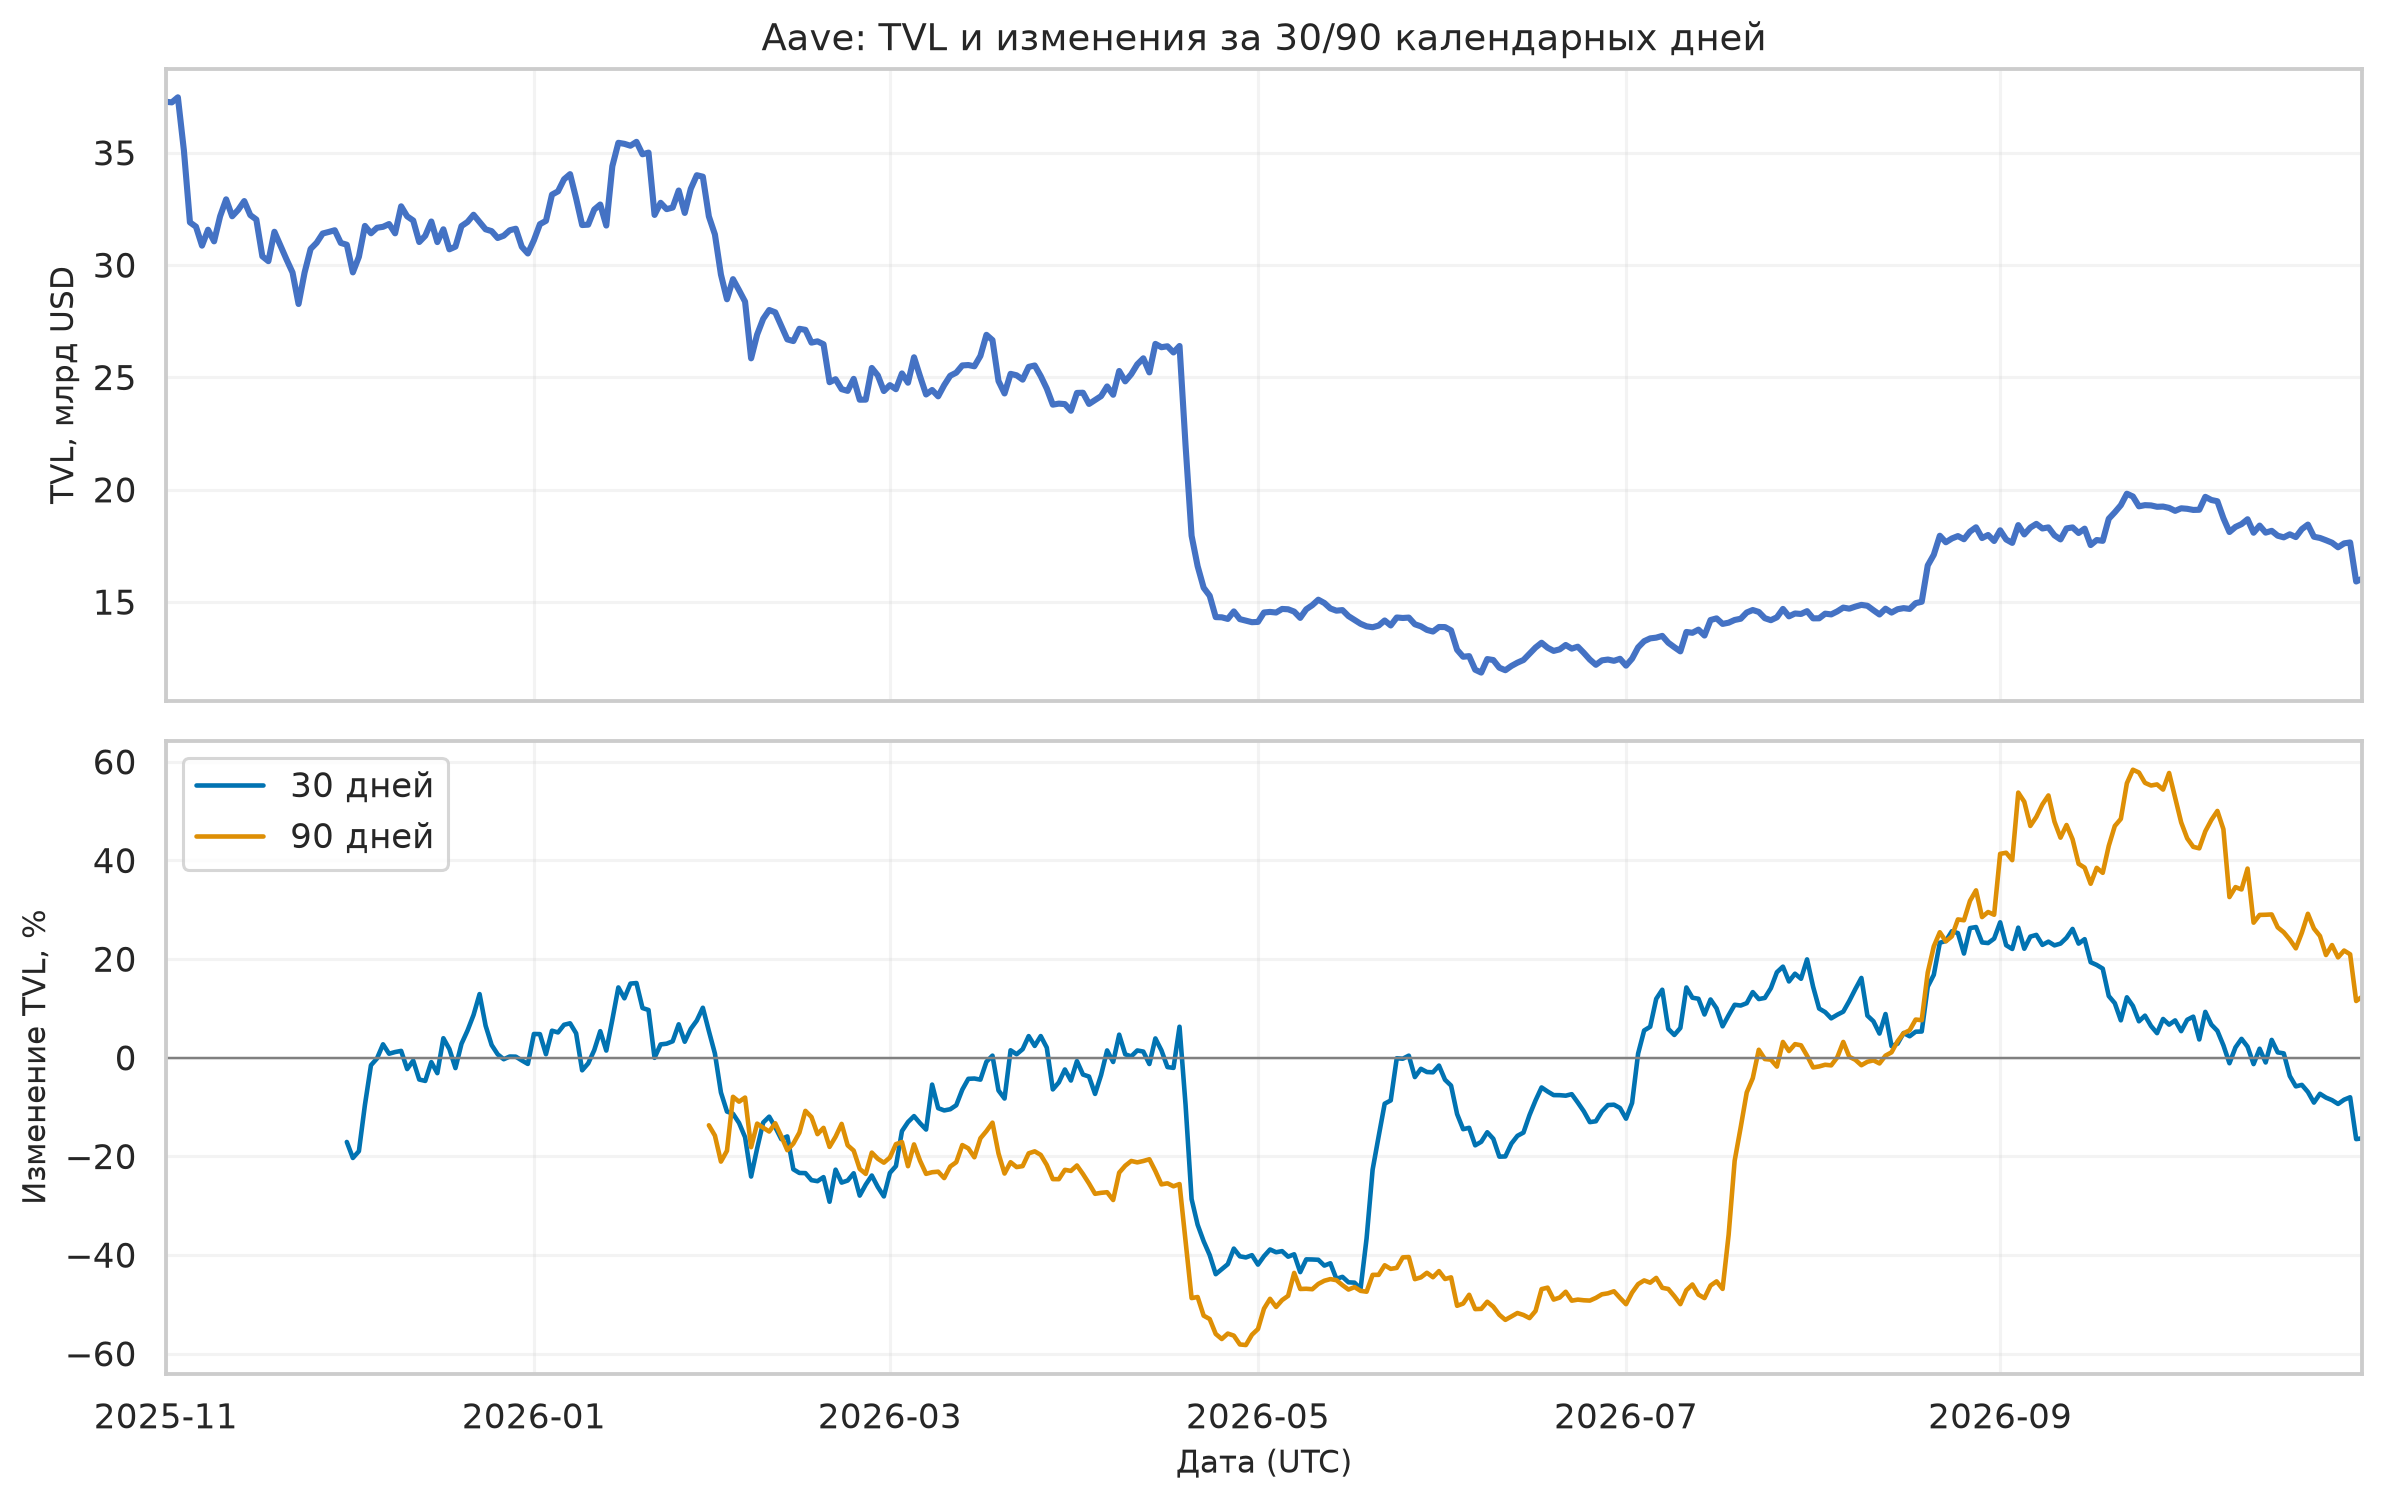

In [6]:
display(Image(filename=str(paths["01_tvl"])))

### Распределение TVL по блокчейнам

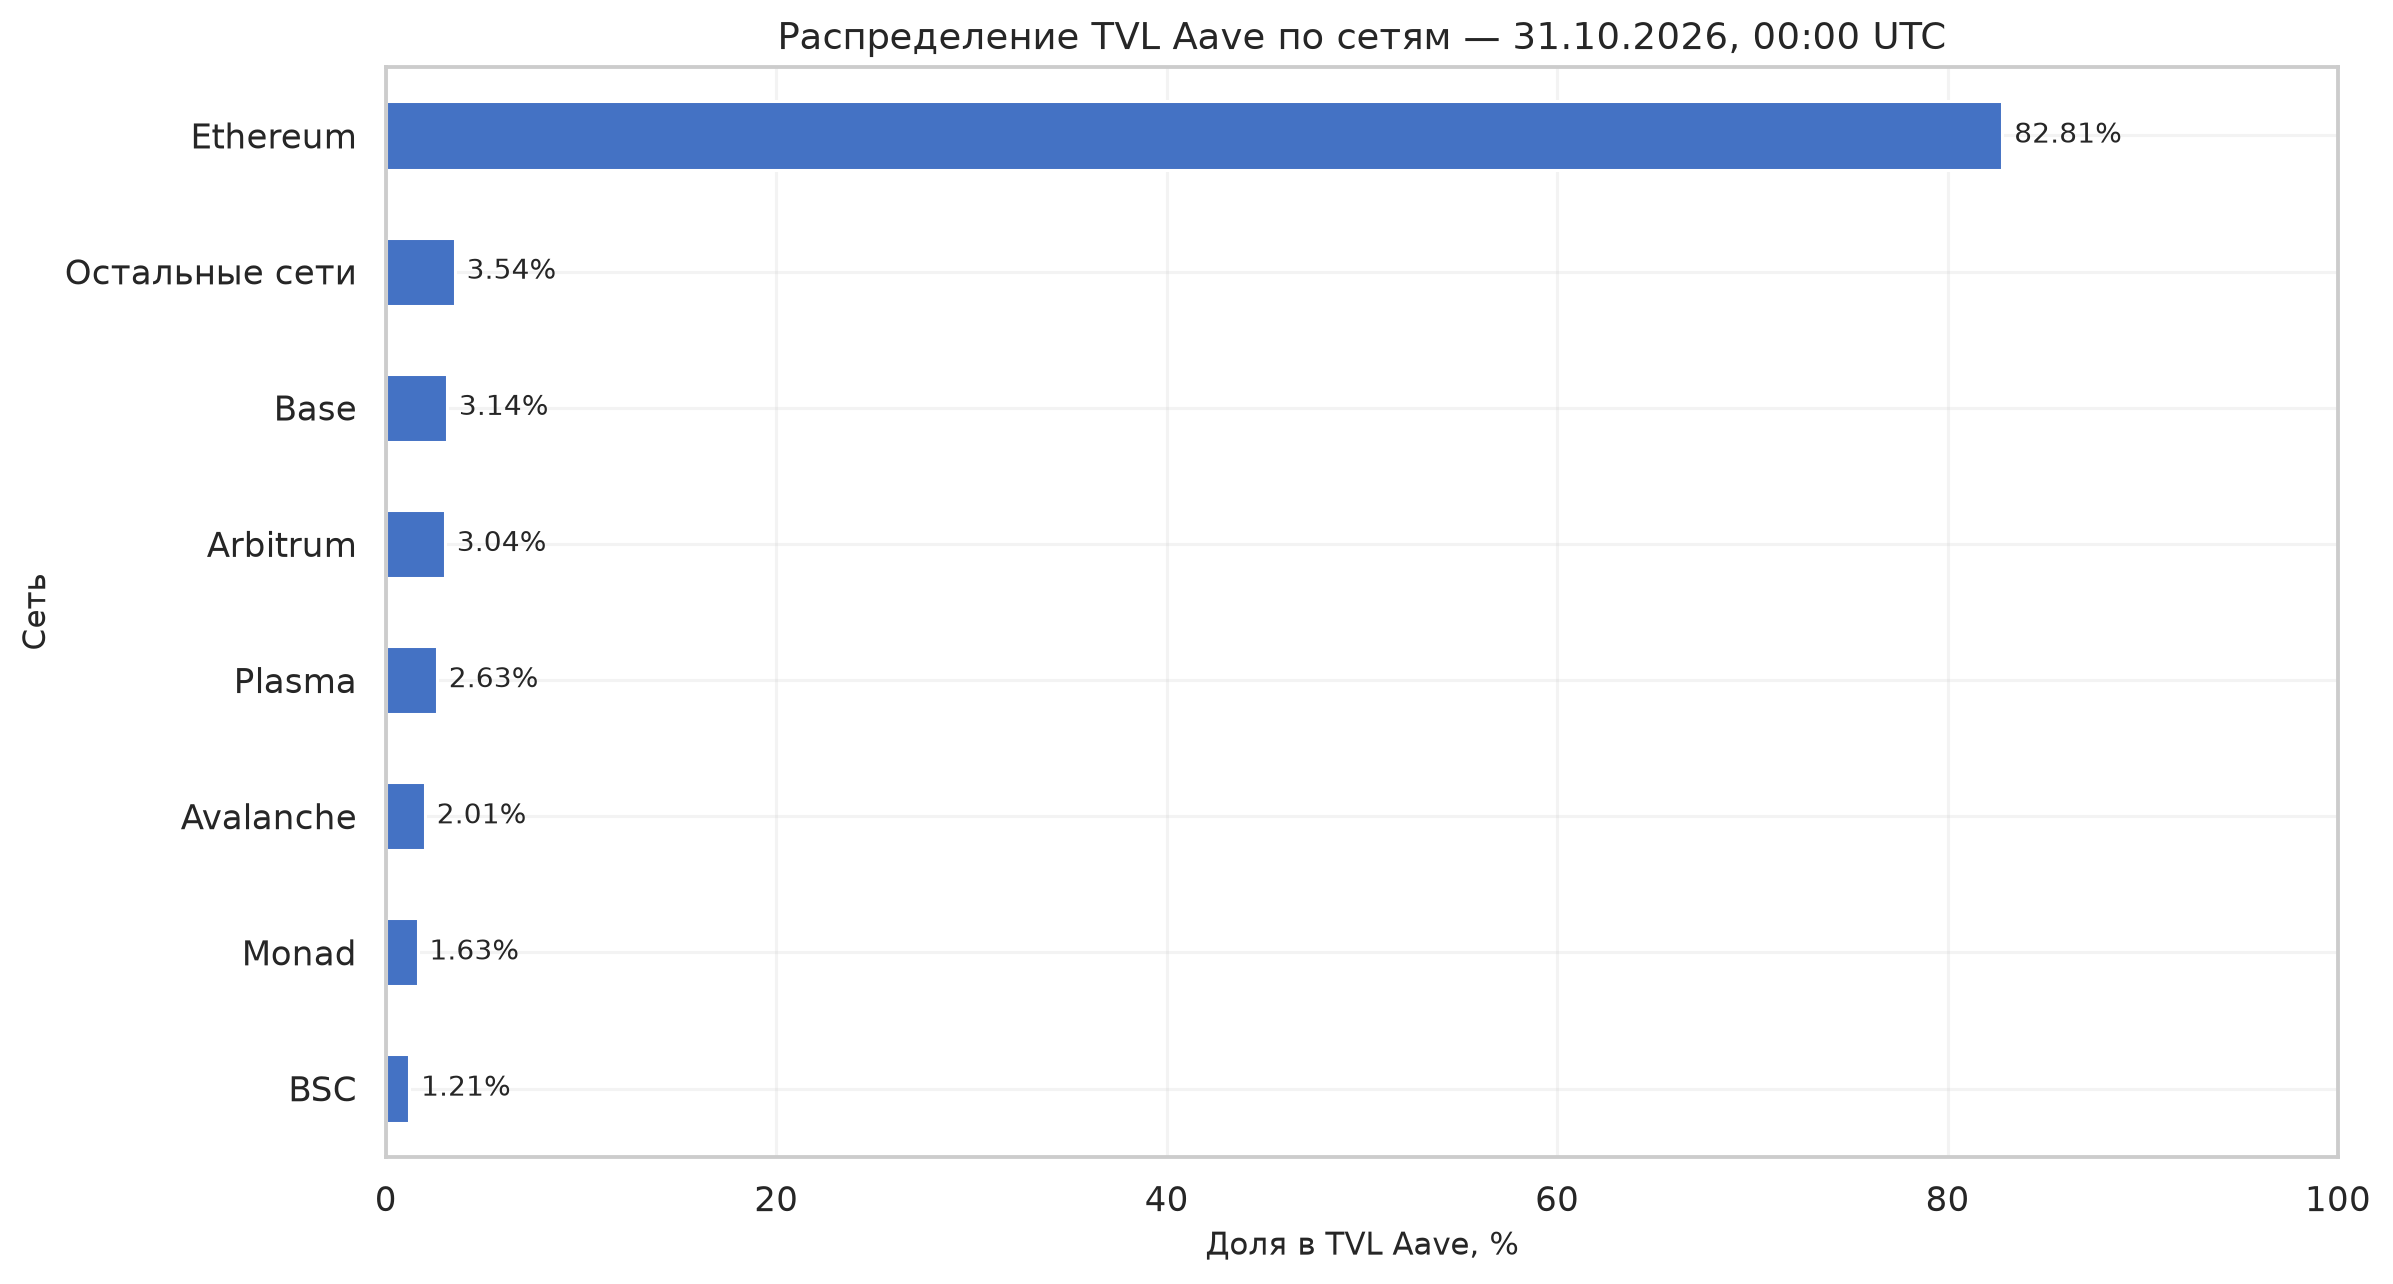

In [7]:
display(Image(filename=str(paths["03_chains"])))

### Fees и protocol revenue

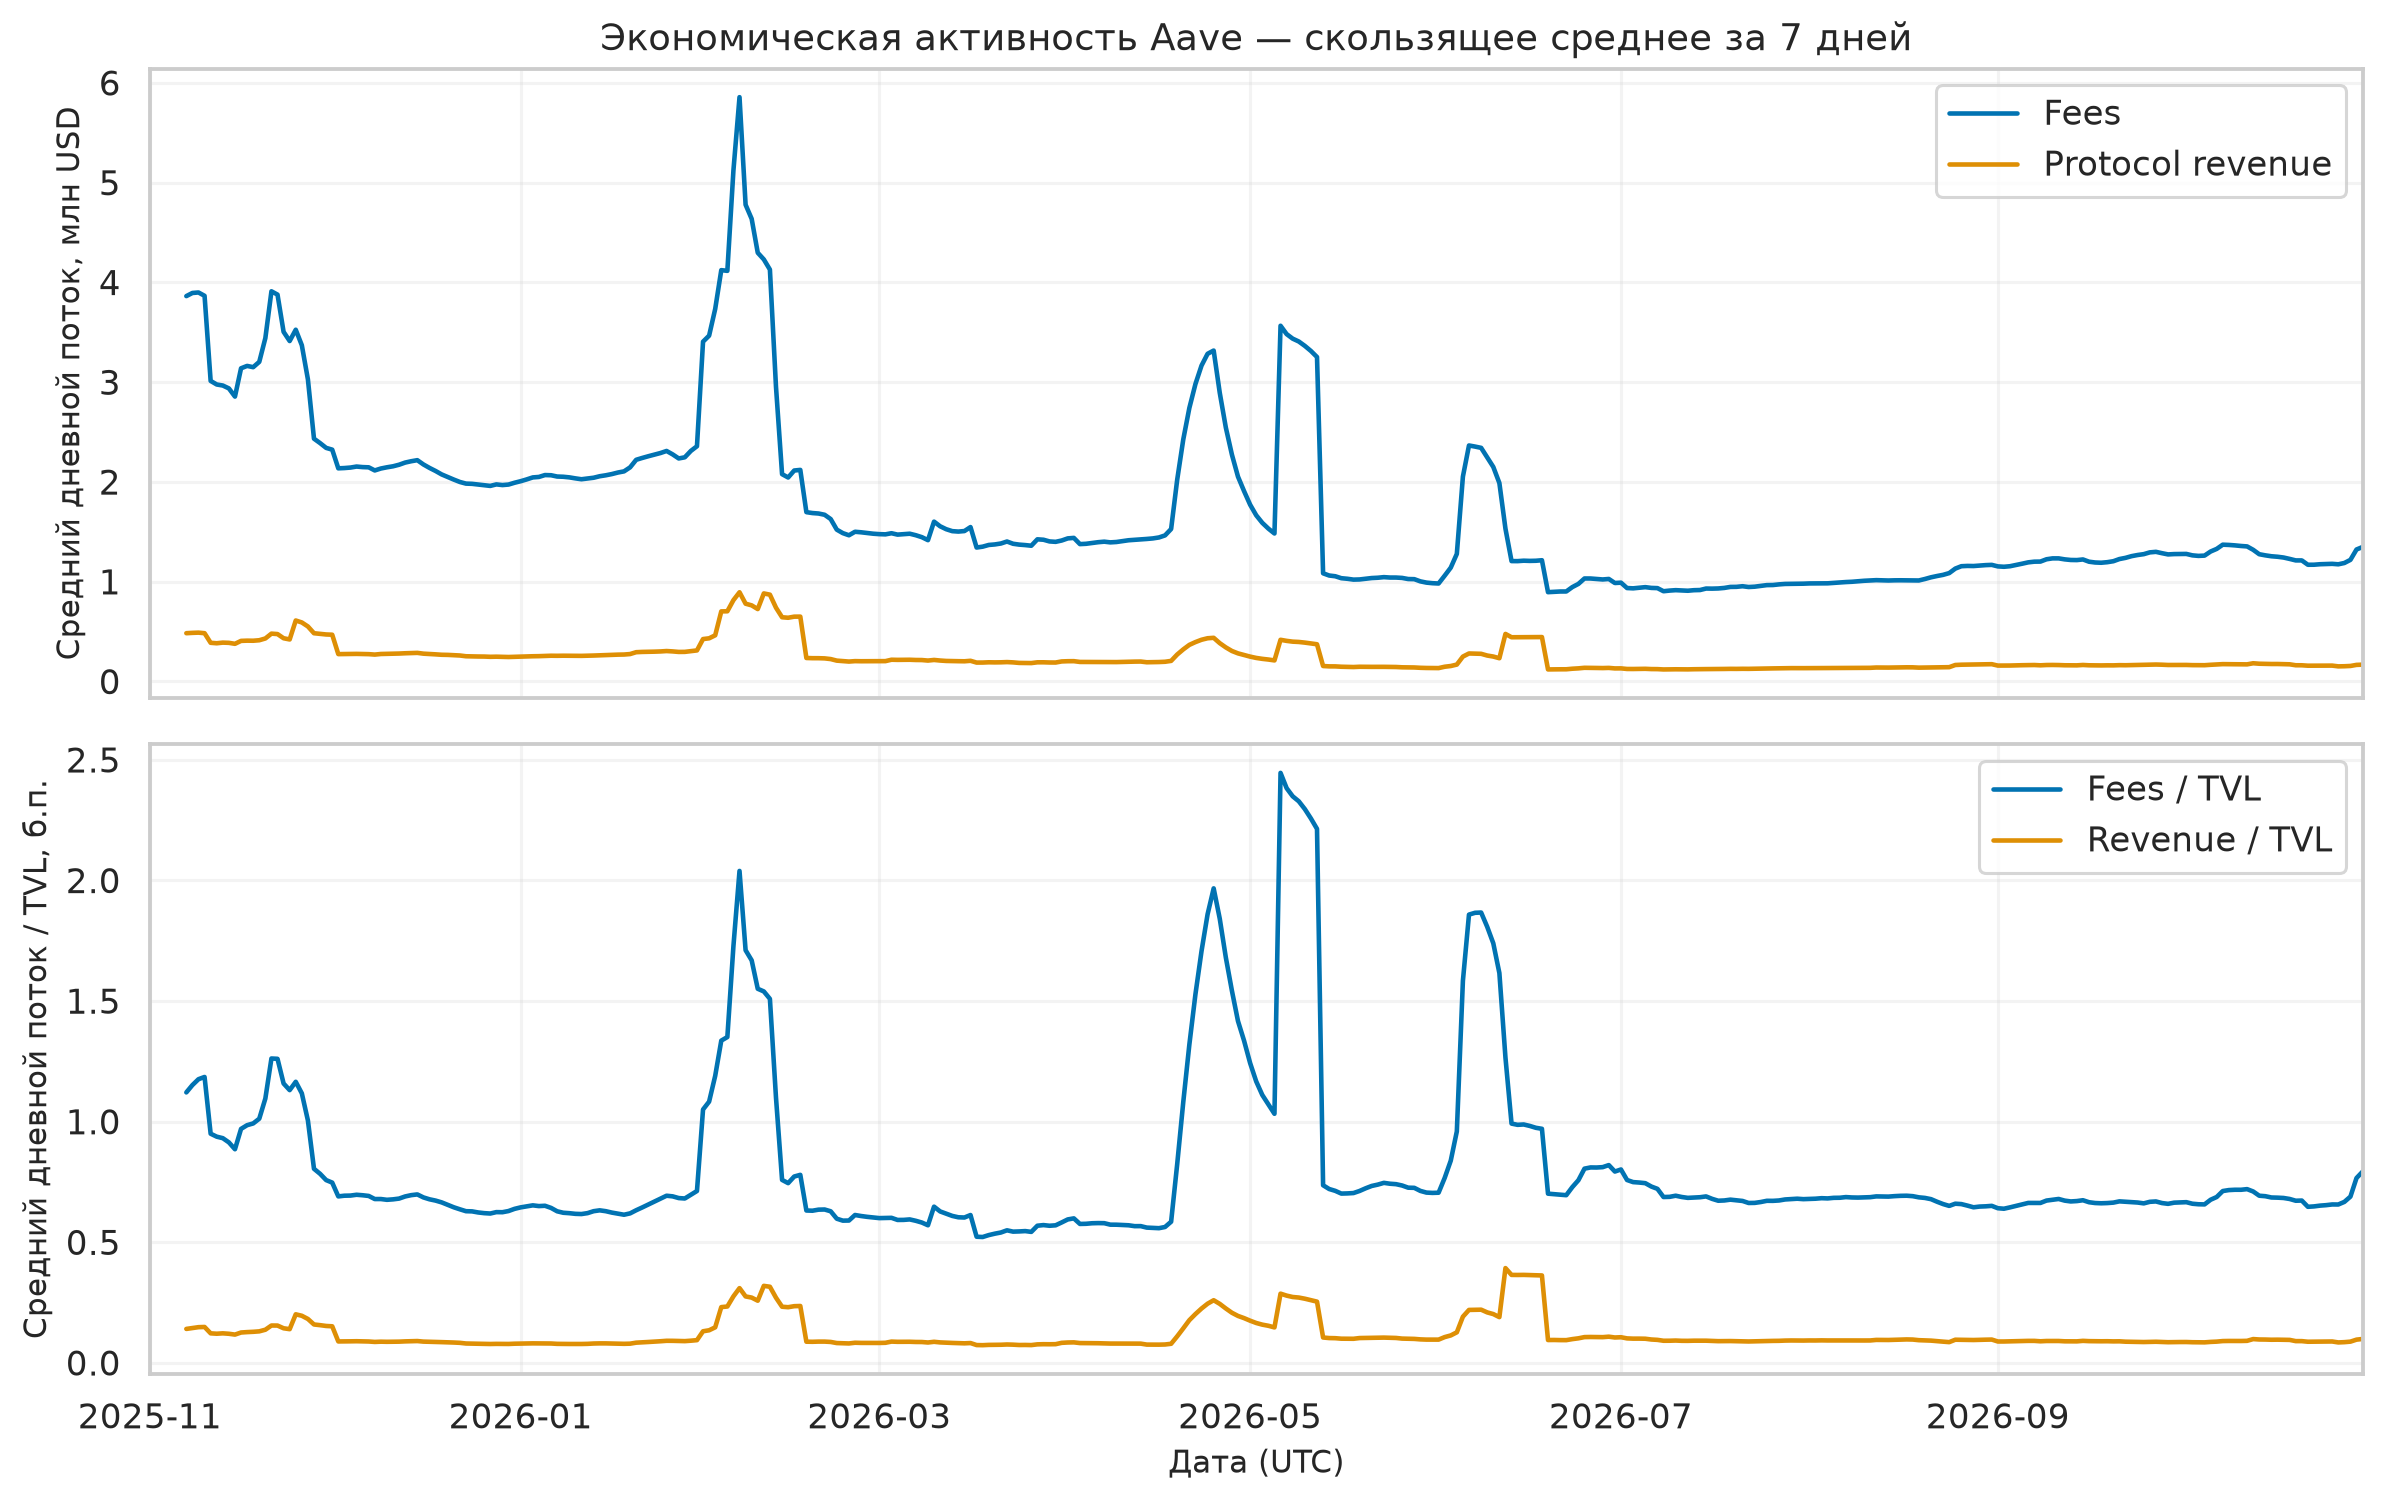

In [8]:
display(Image(filename=str(paths["04_economics"])))

### Lending snapshot трёх резервов

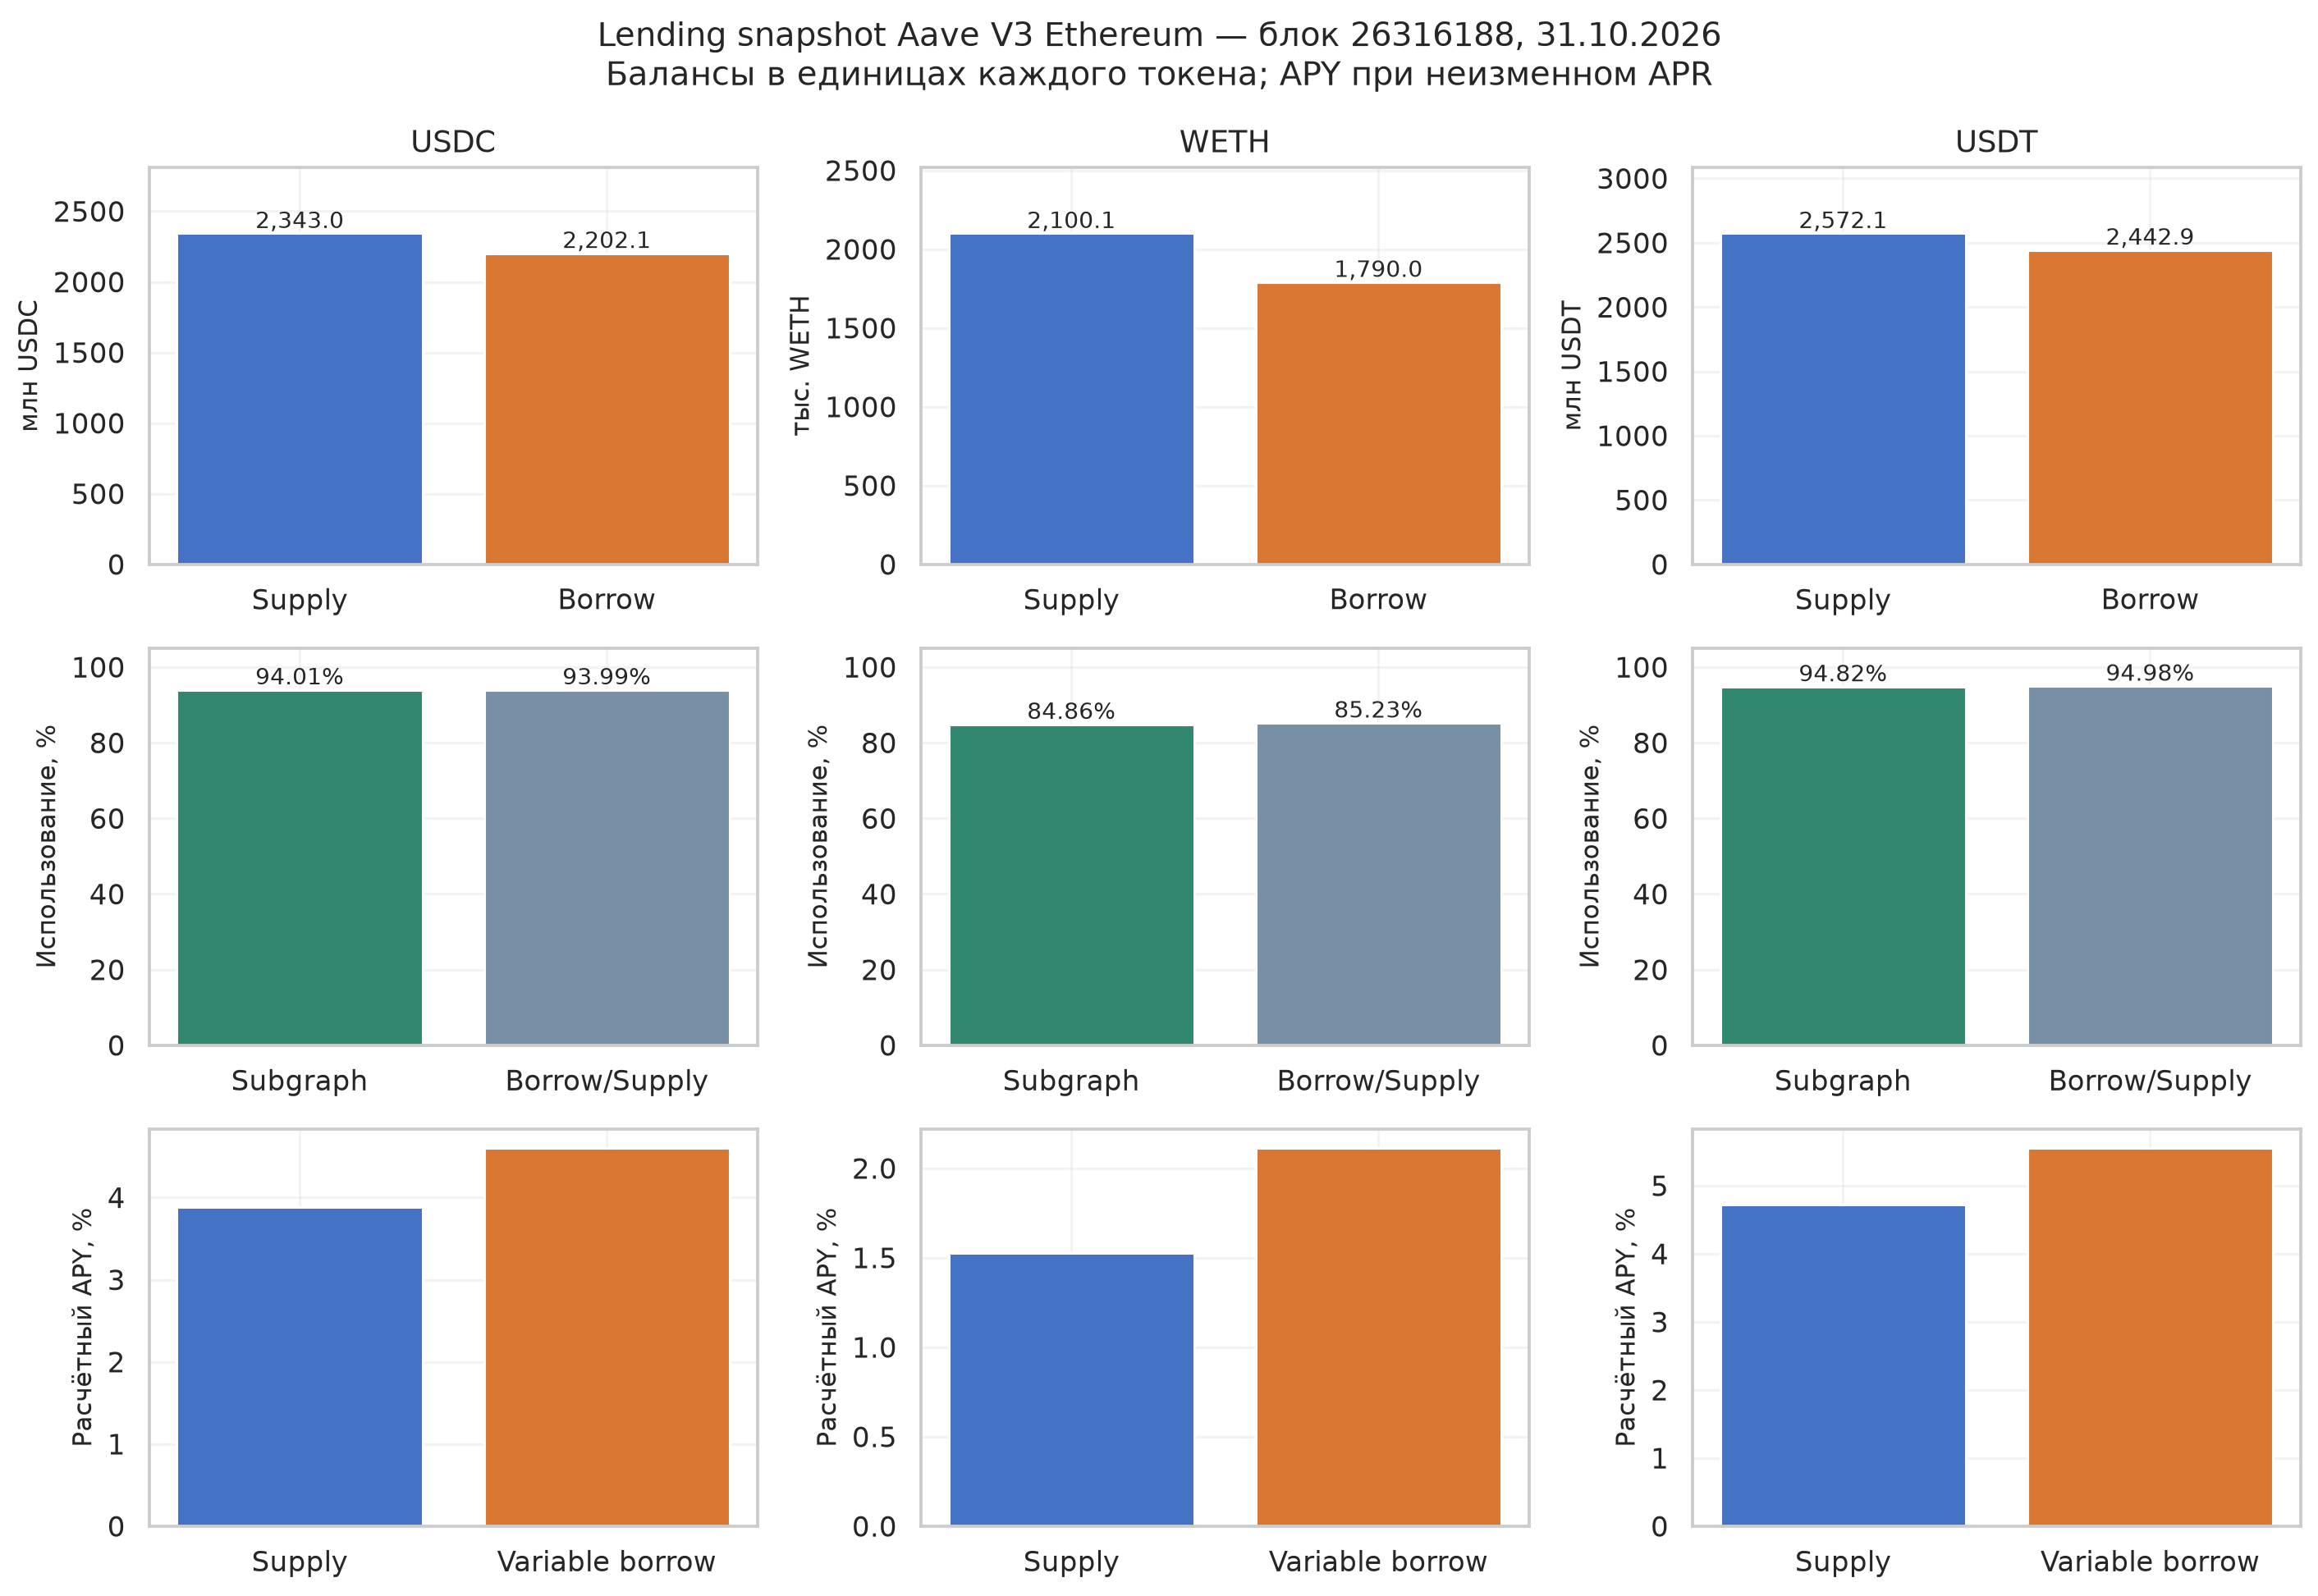

In [9]:
display(Image(filename=str(paths["05_lending_snapshot"])))

## Token Analysis

### Цена AAVE

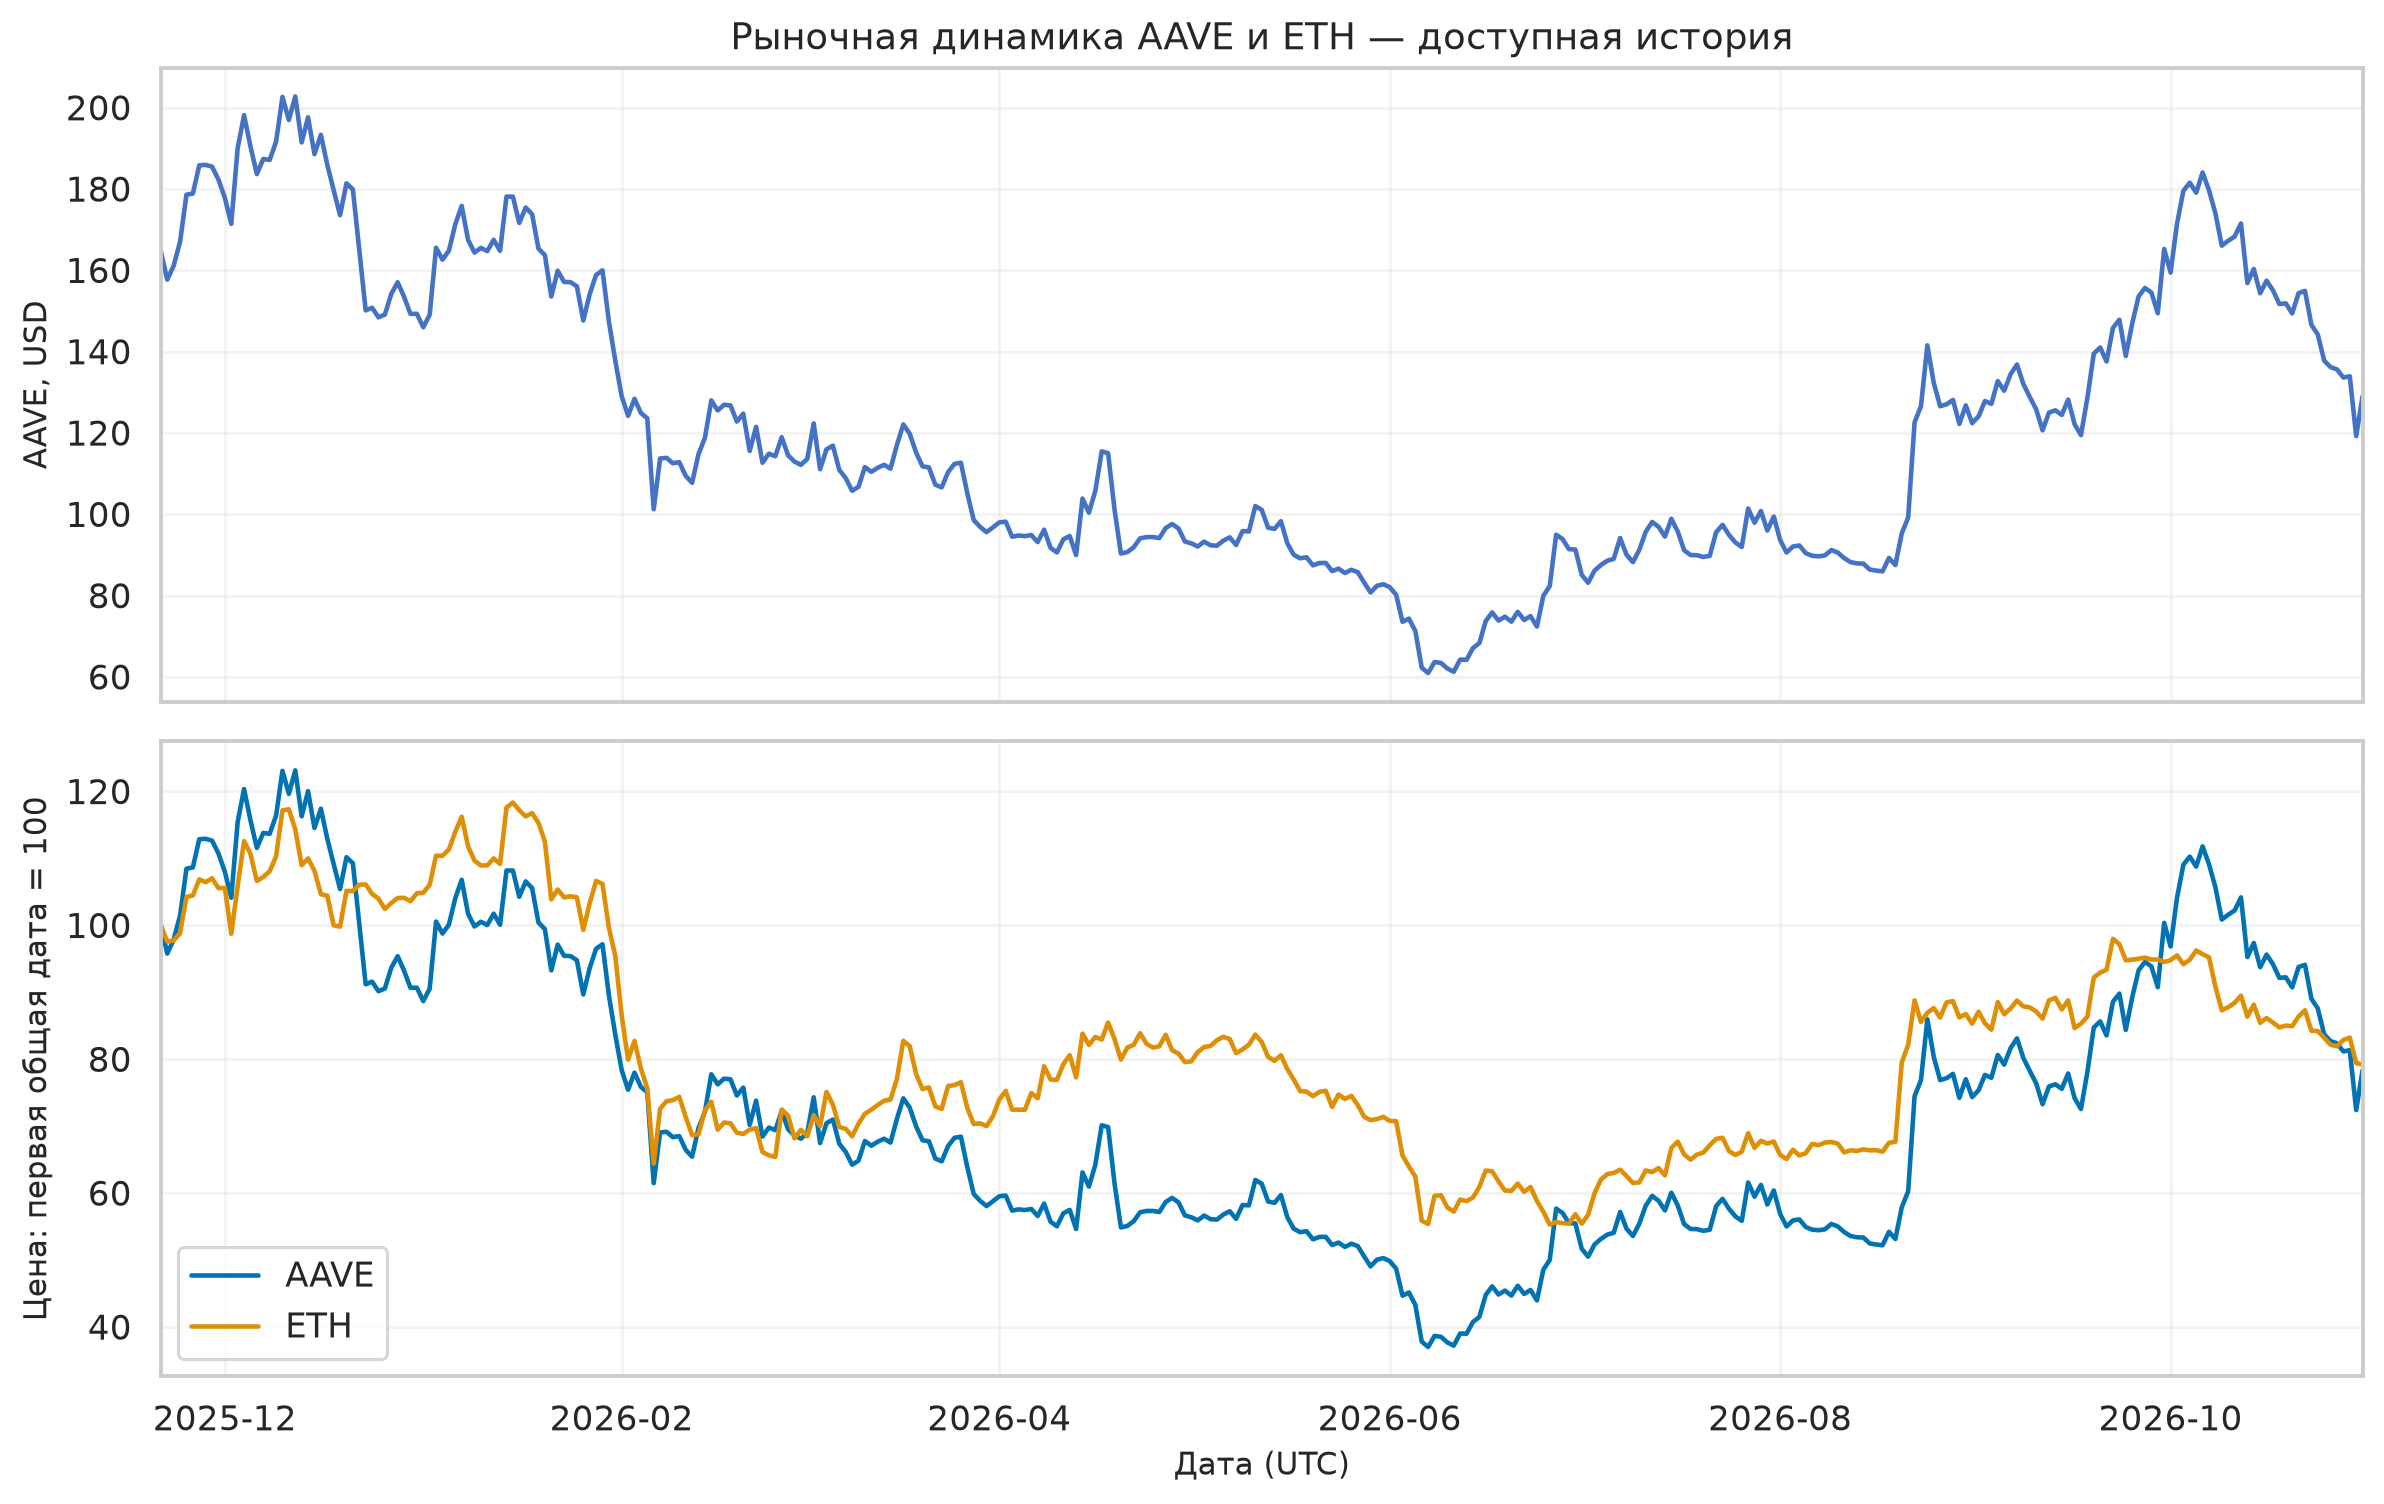

In [10]:
display(Image(filename=str(paths["06_token_prices"])))

### Доходности и реализованная волатильность

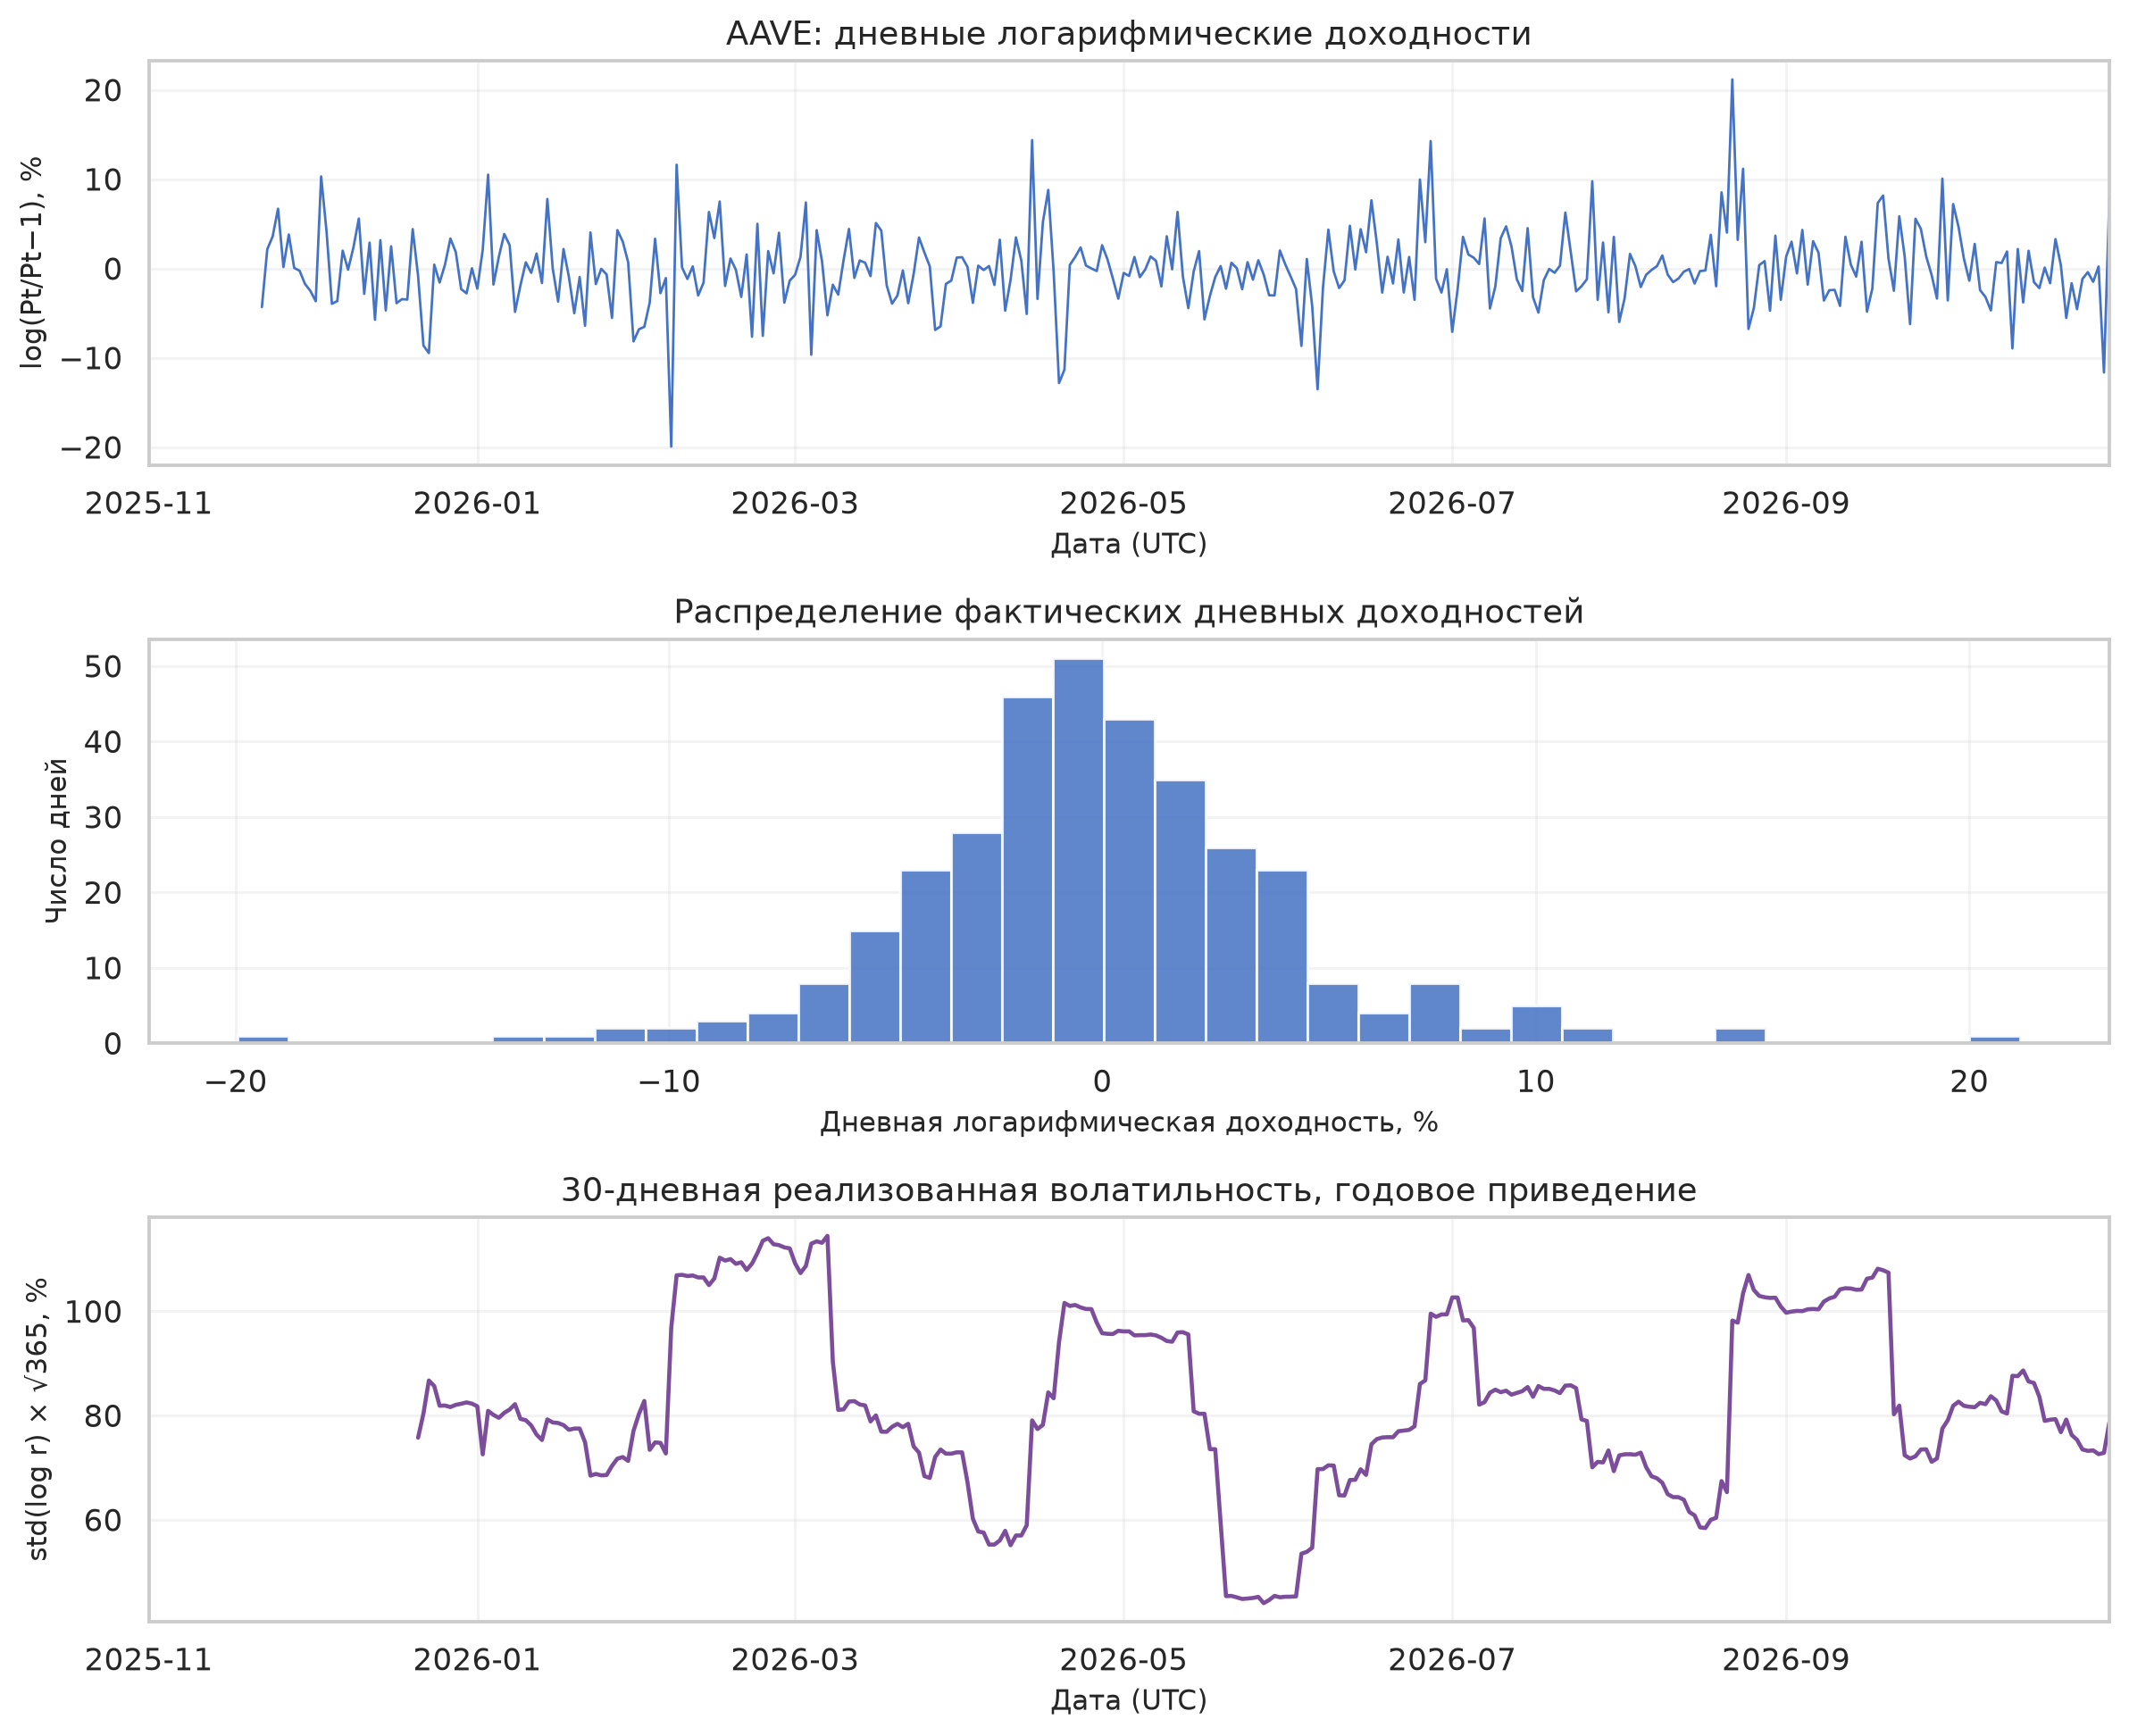

In [11]:
display(Image(filename=str(paths["07_returns_volatility"])))

### Капитализация и Market Cap / TVL

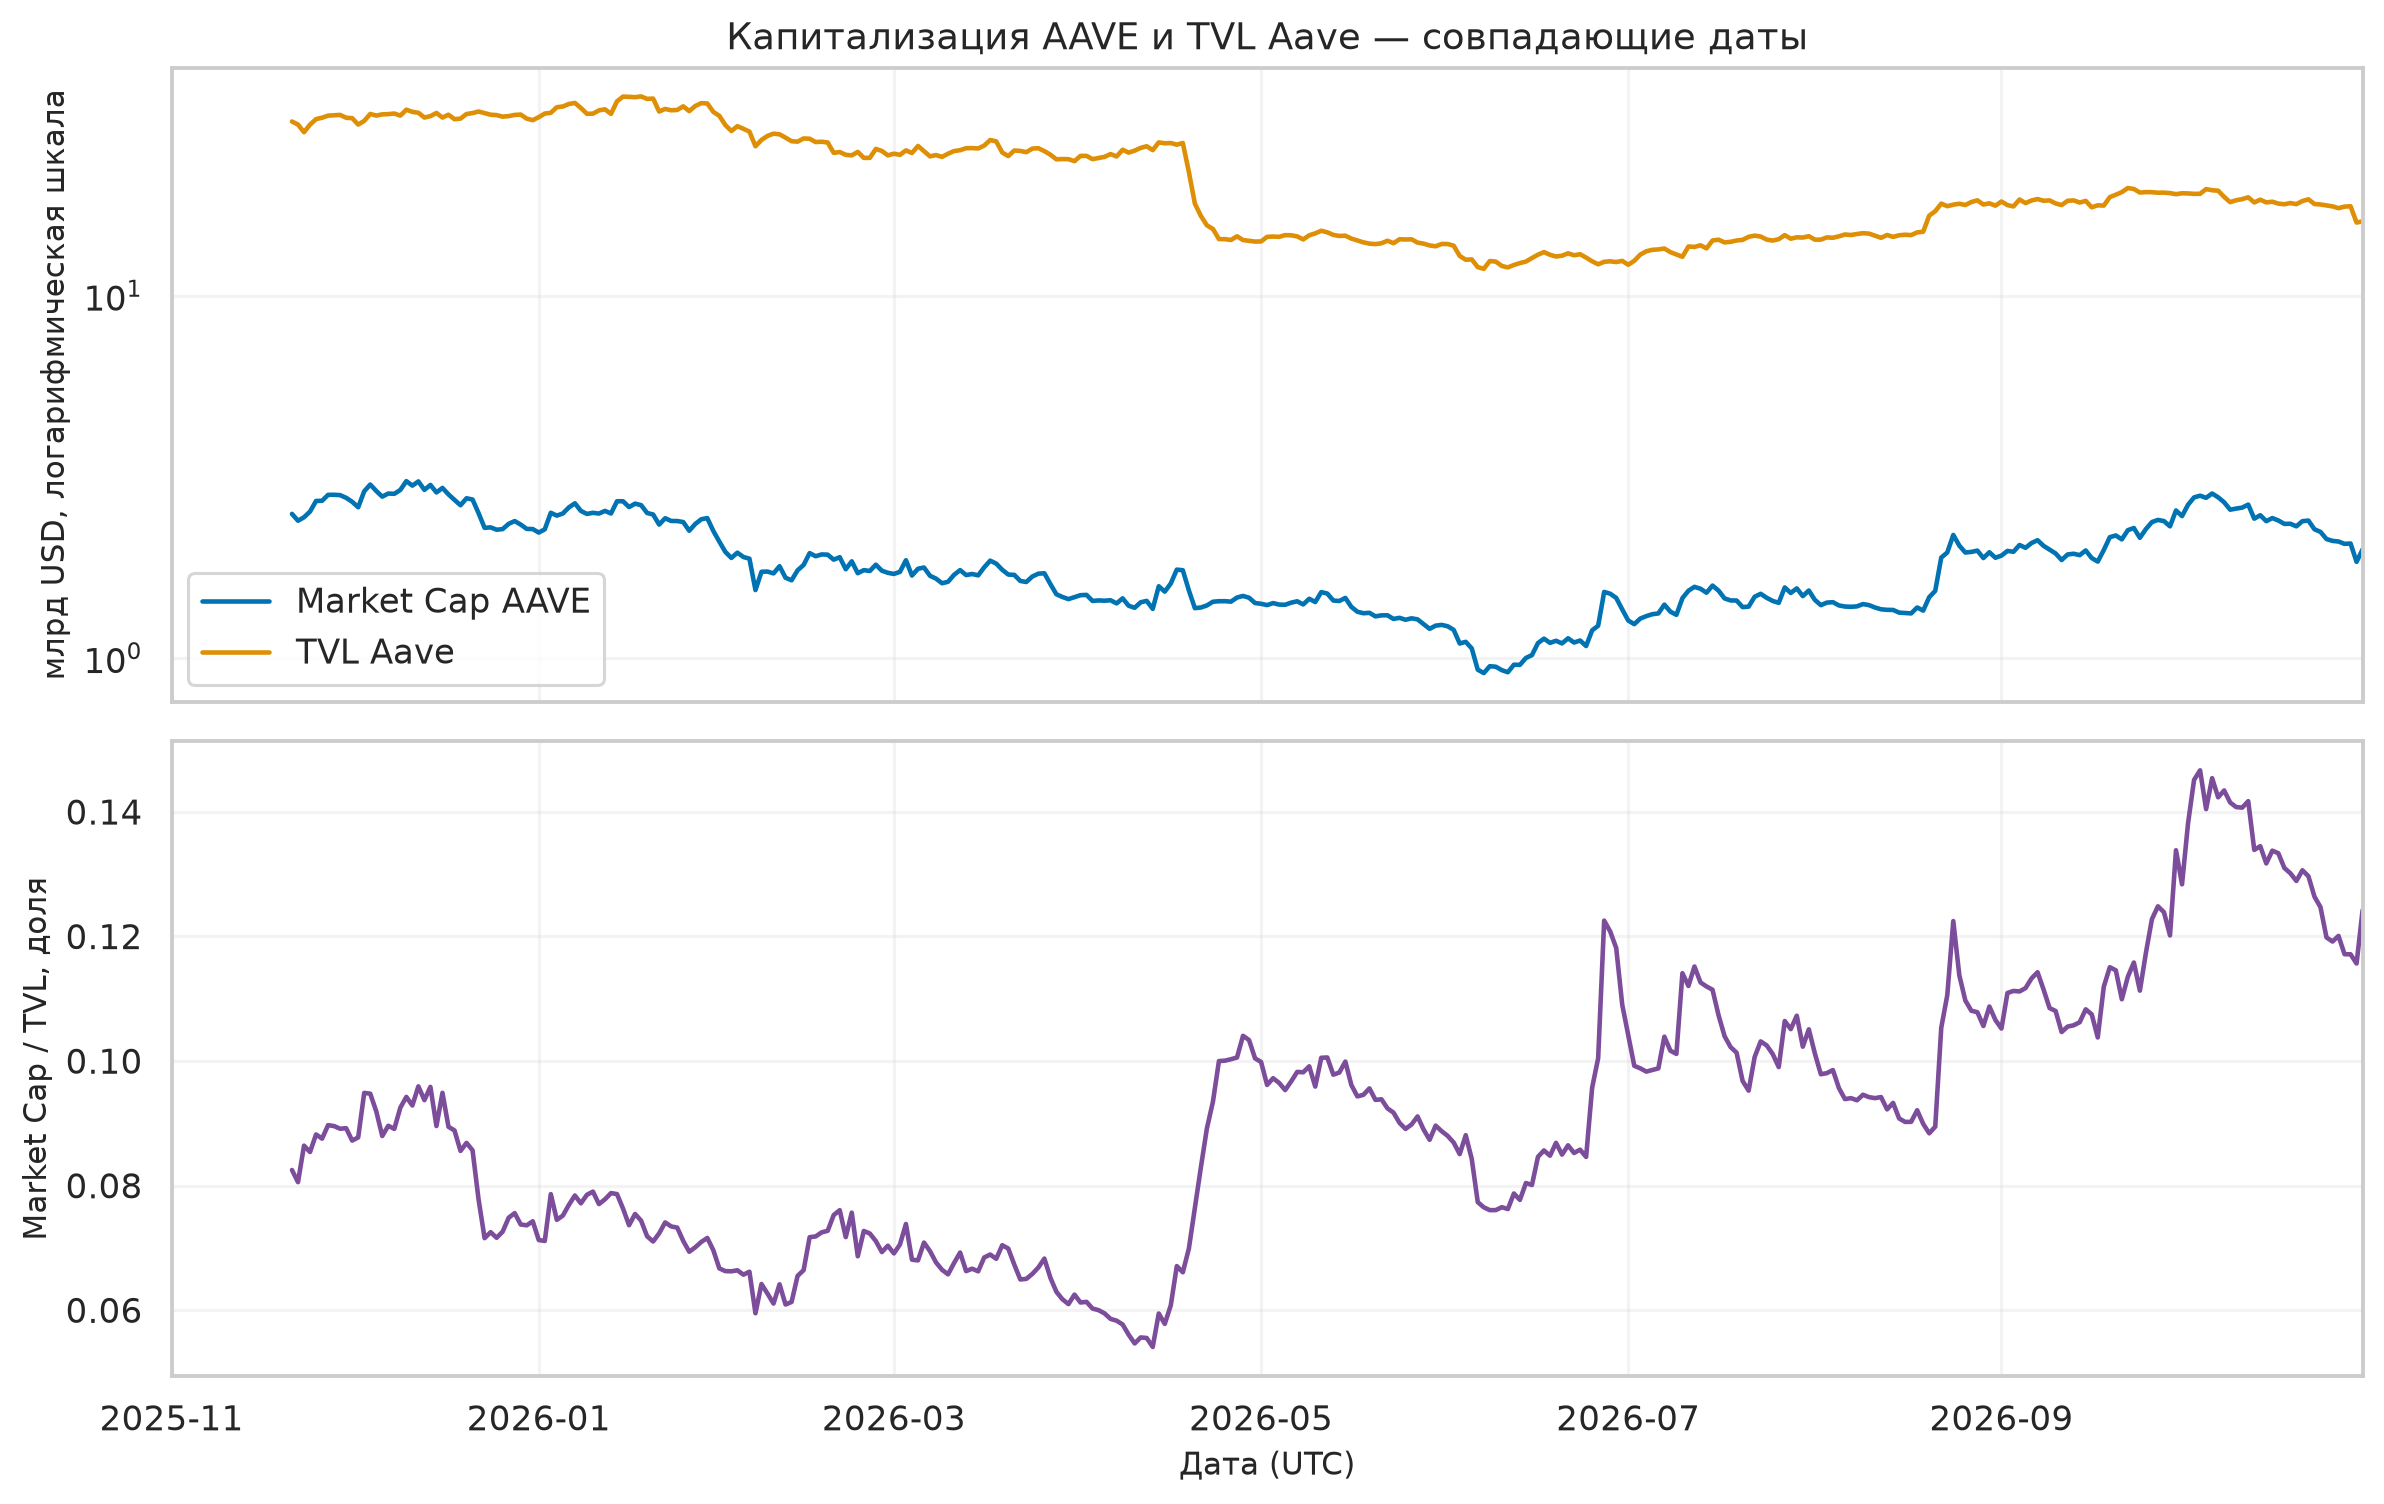

In [12]:
display(Image(filename=str(paths["08_valuation"])))

## Competitor Analysis

### Aave, Morpho и Compound

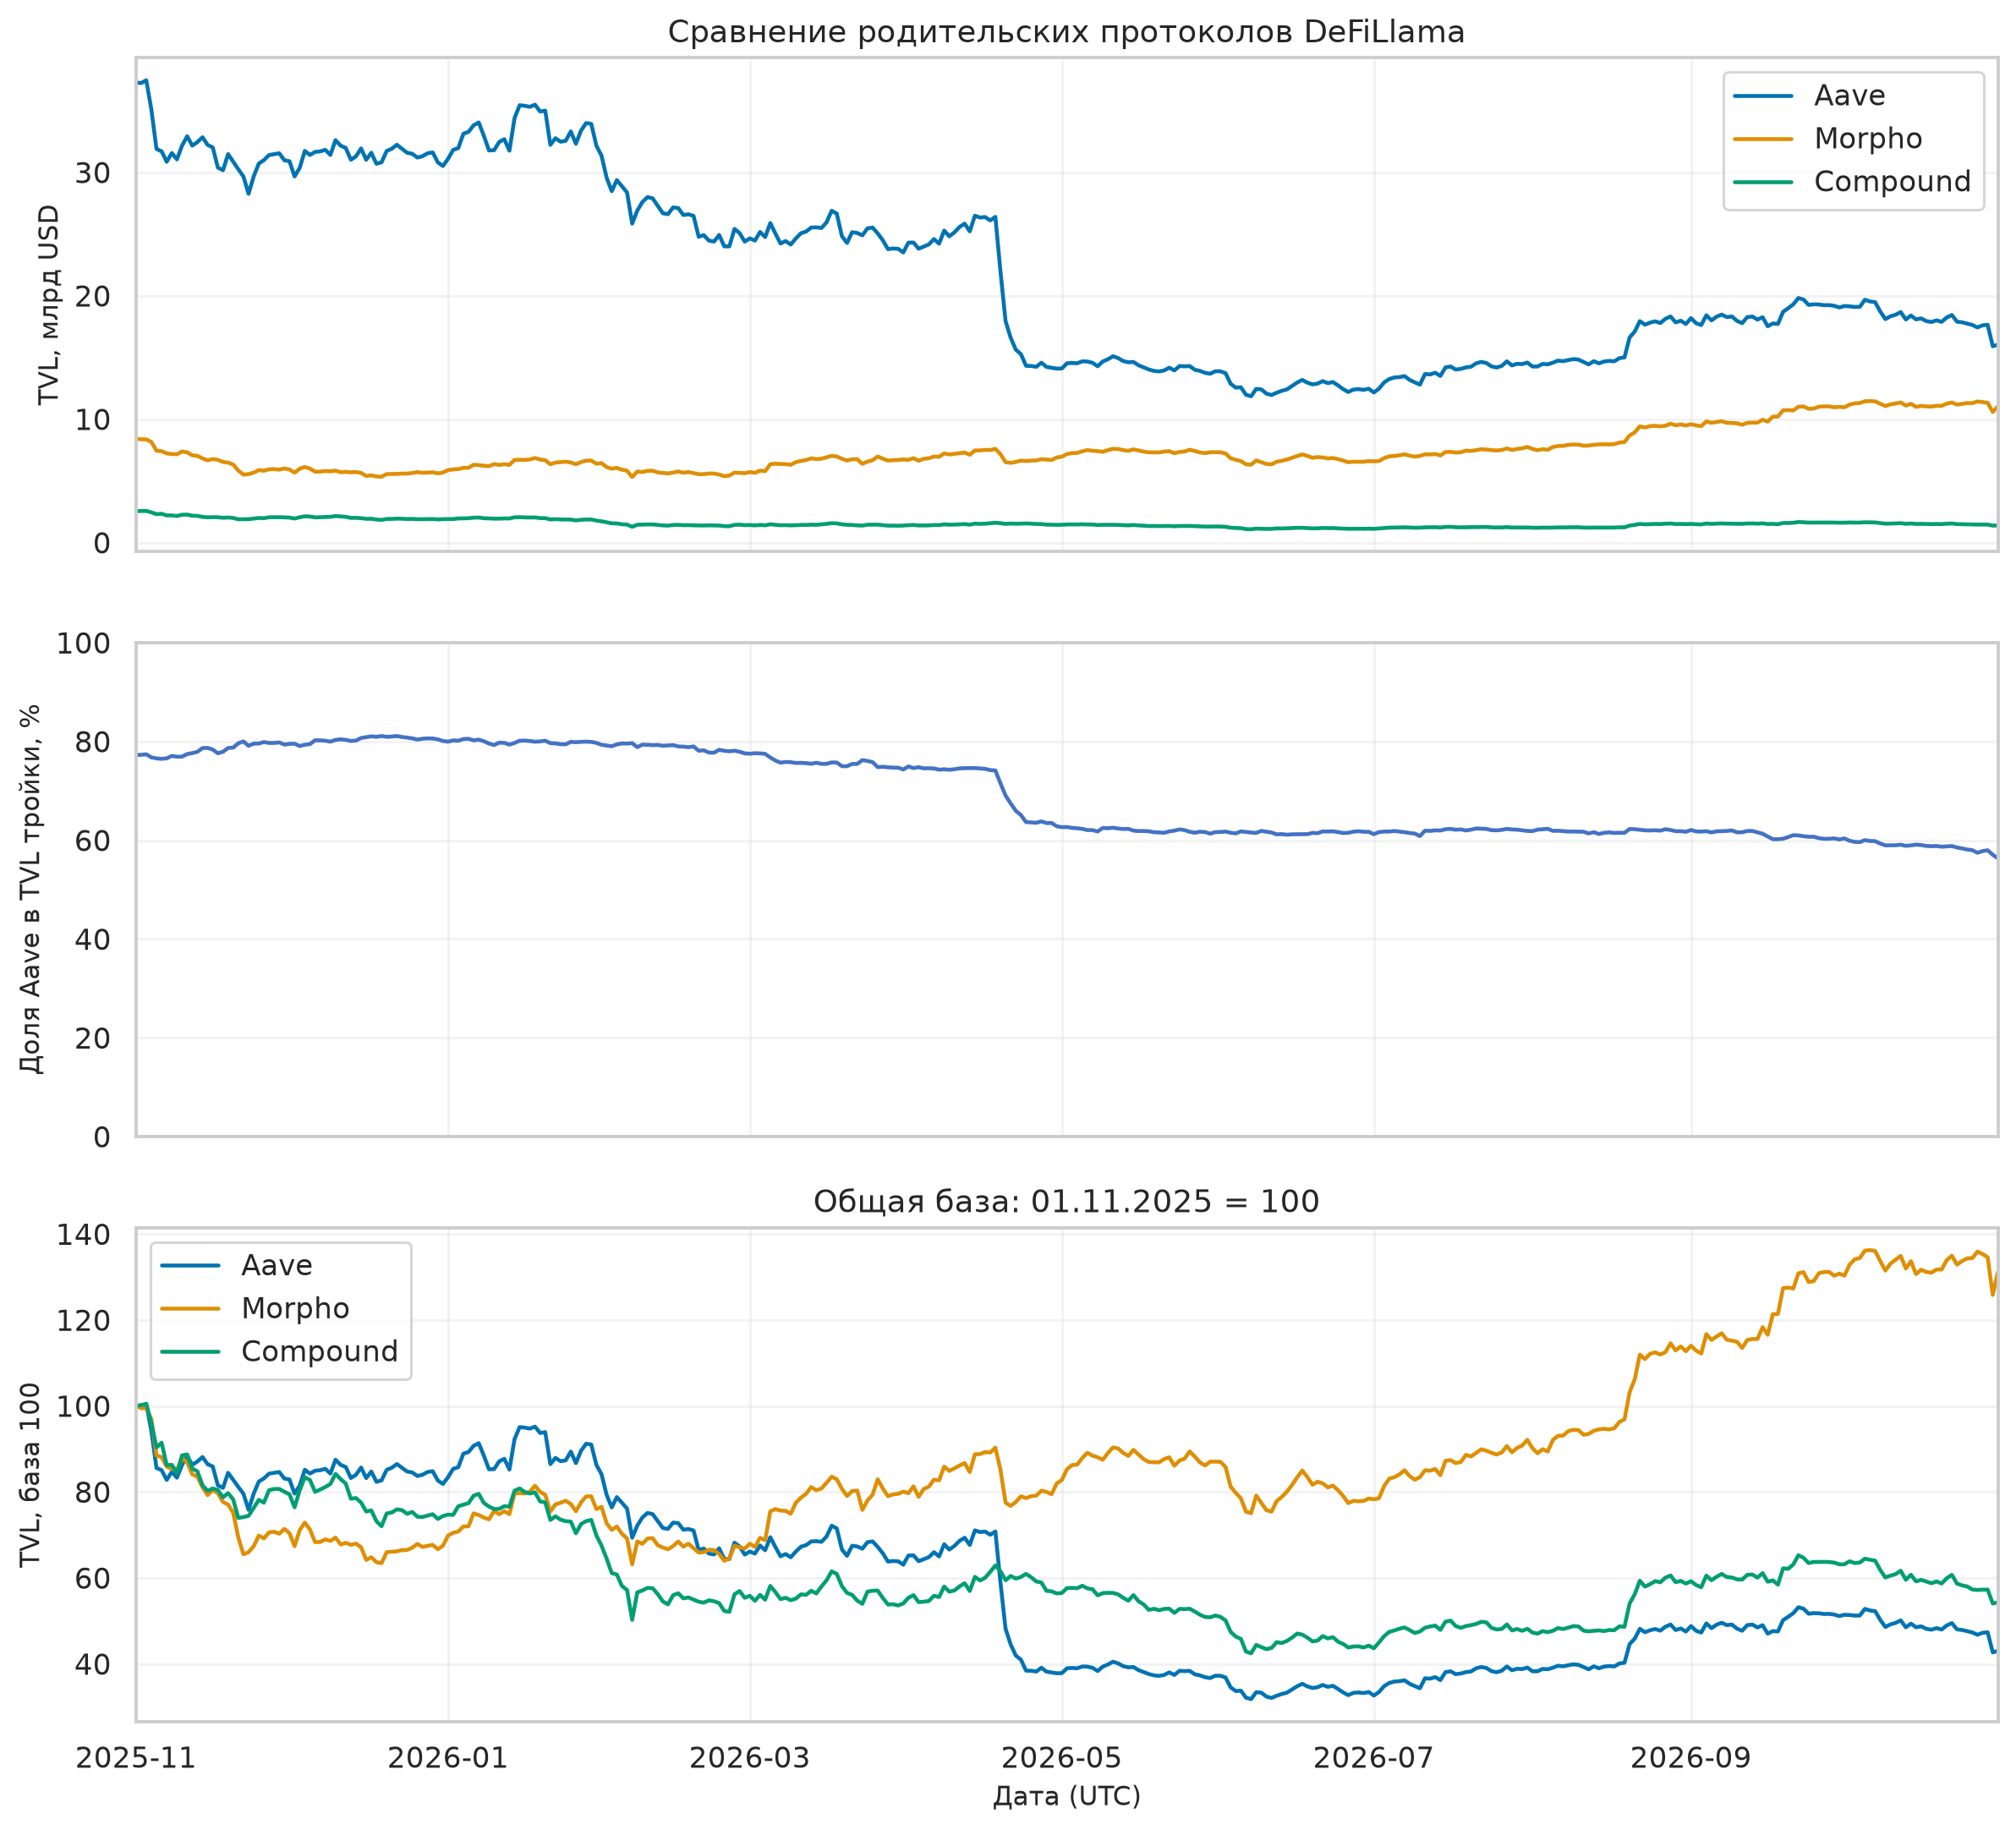

In [13]:
display(Image(filename=str(paths["02_competitors"])))

## On-chain Analysis

### Дневные изменения

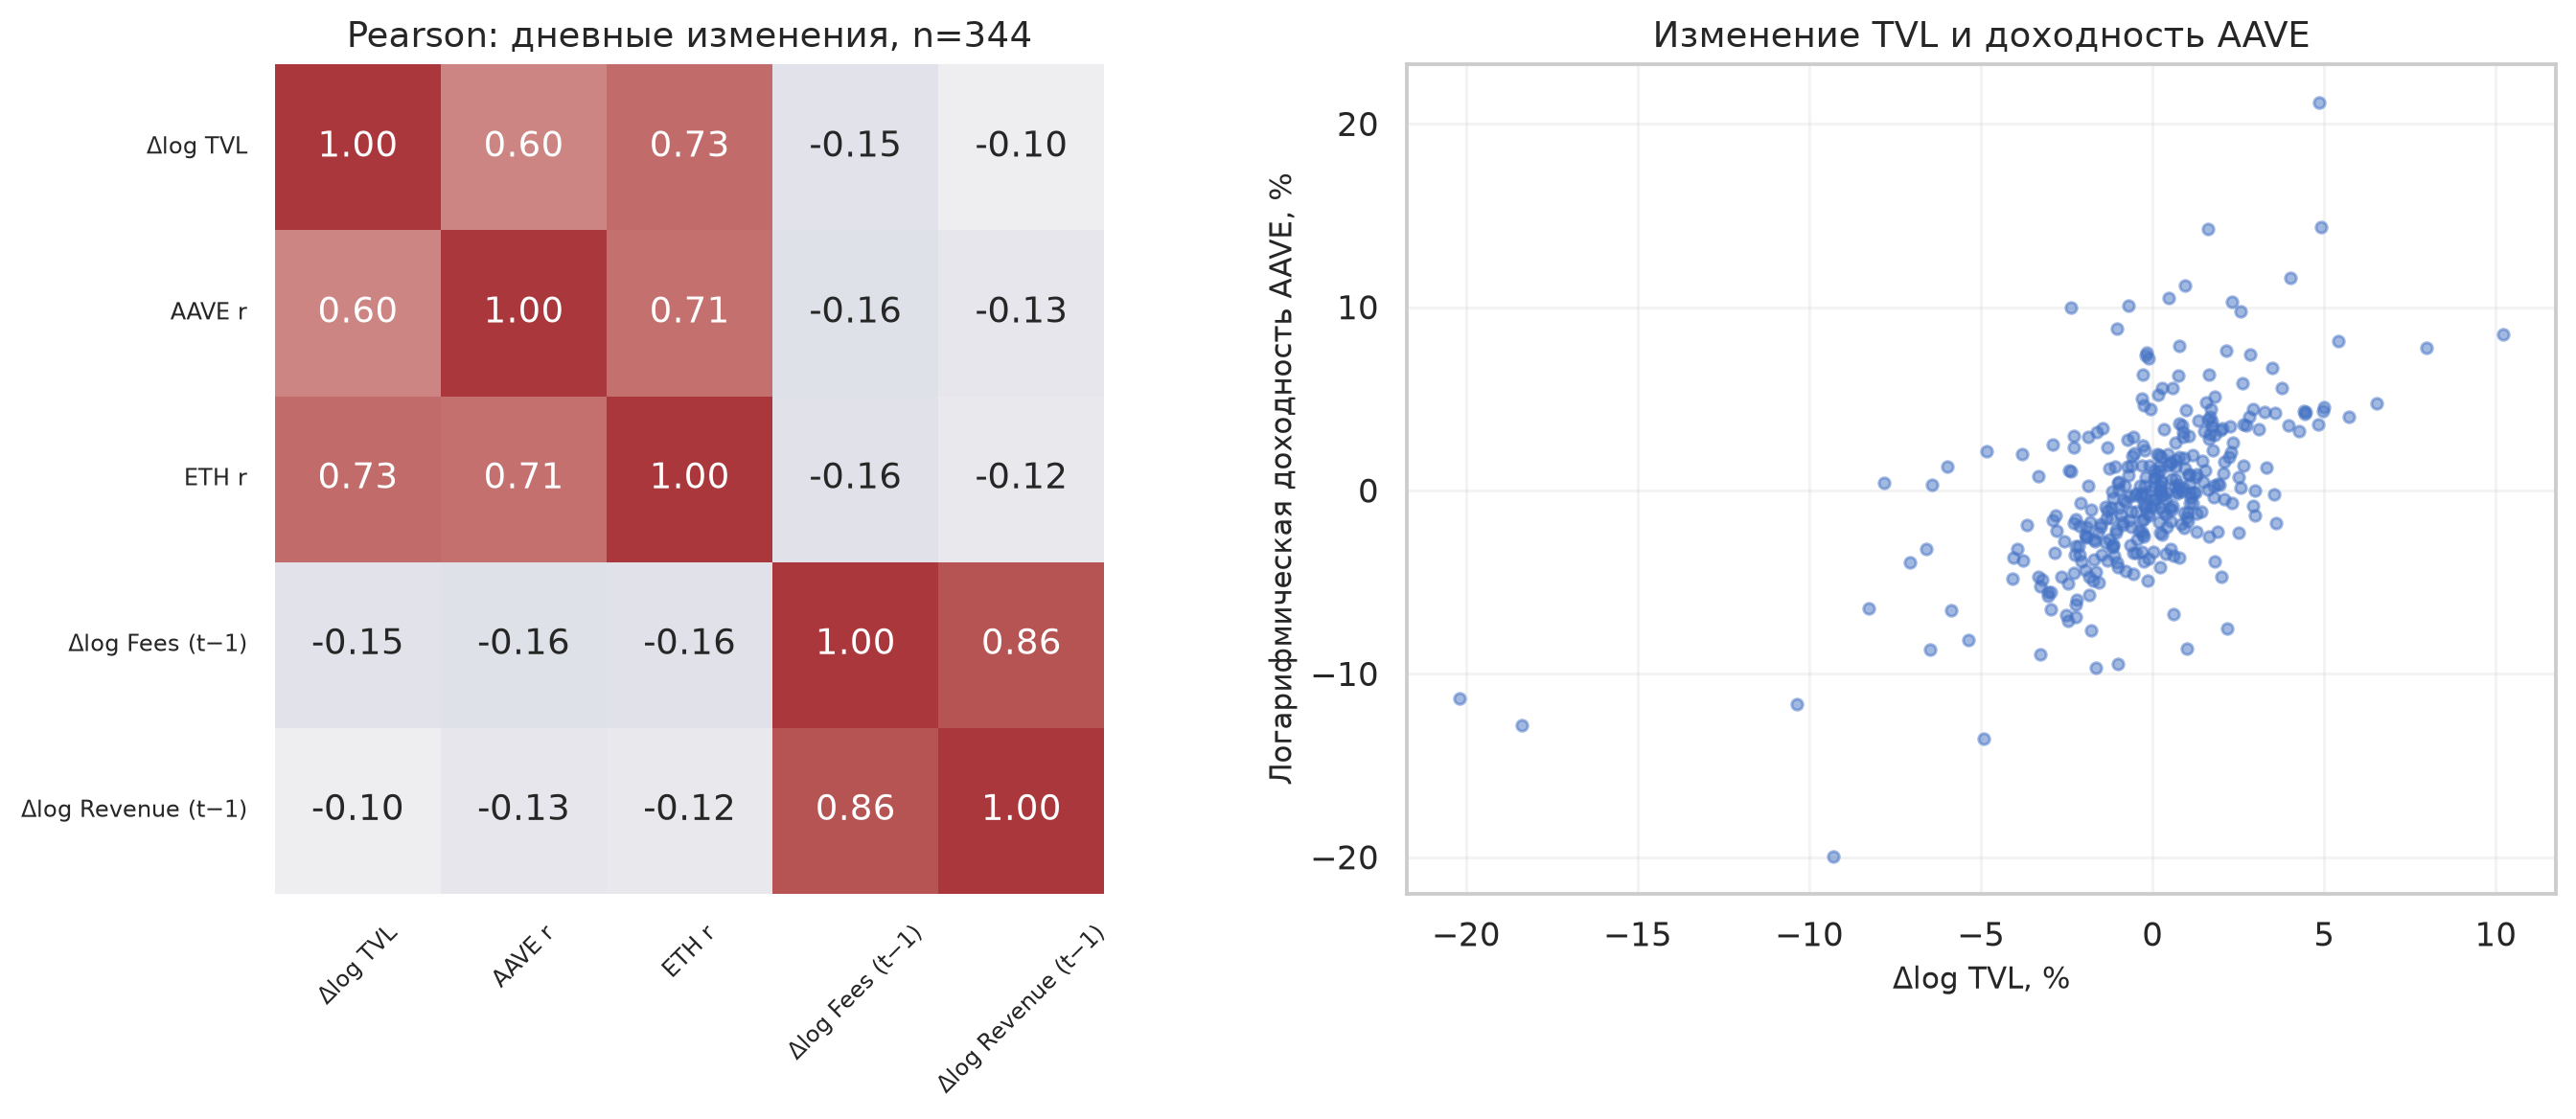

In [14]:
display(Image(filename=str(paths["09_associations"])))

### Однодневный on-chain case study

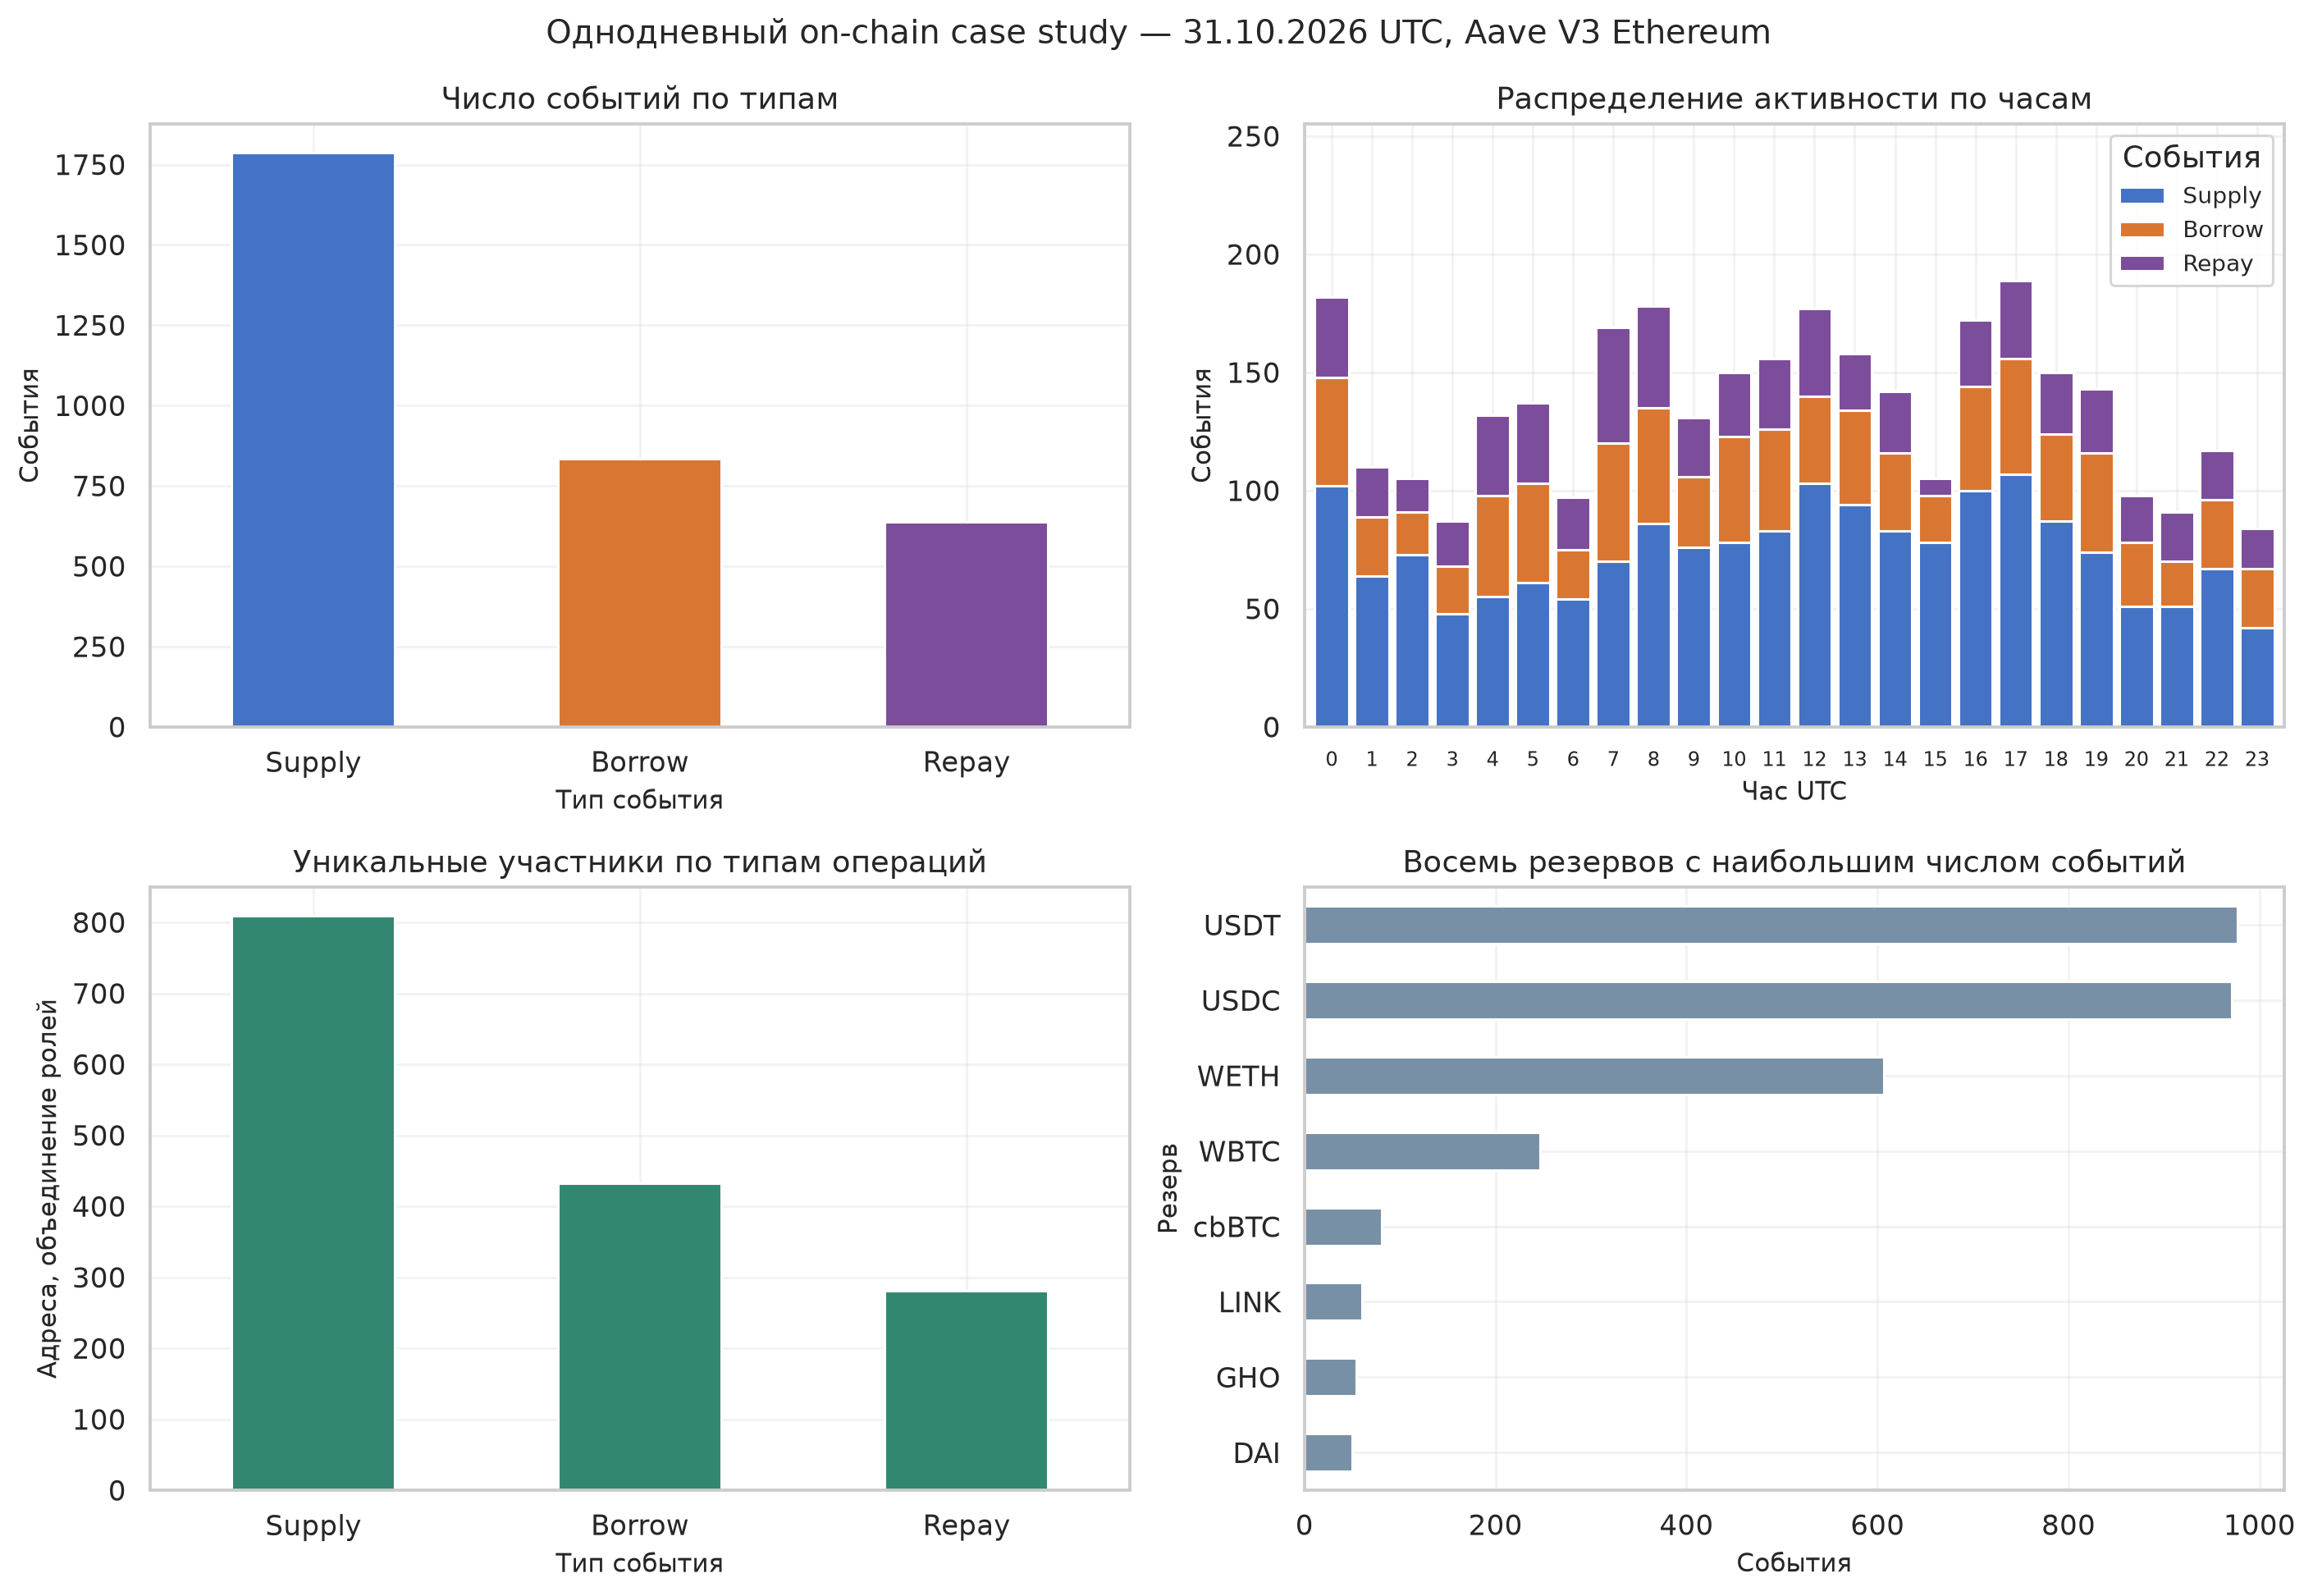

In [15]:
display(Image(filename=str(paths["10_onchain_case"])))

### 30-дневная история резервов

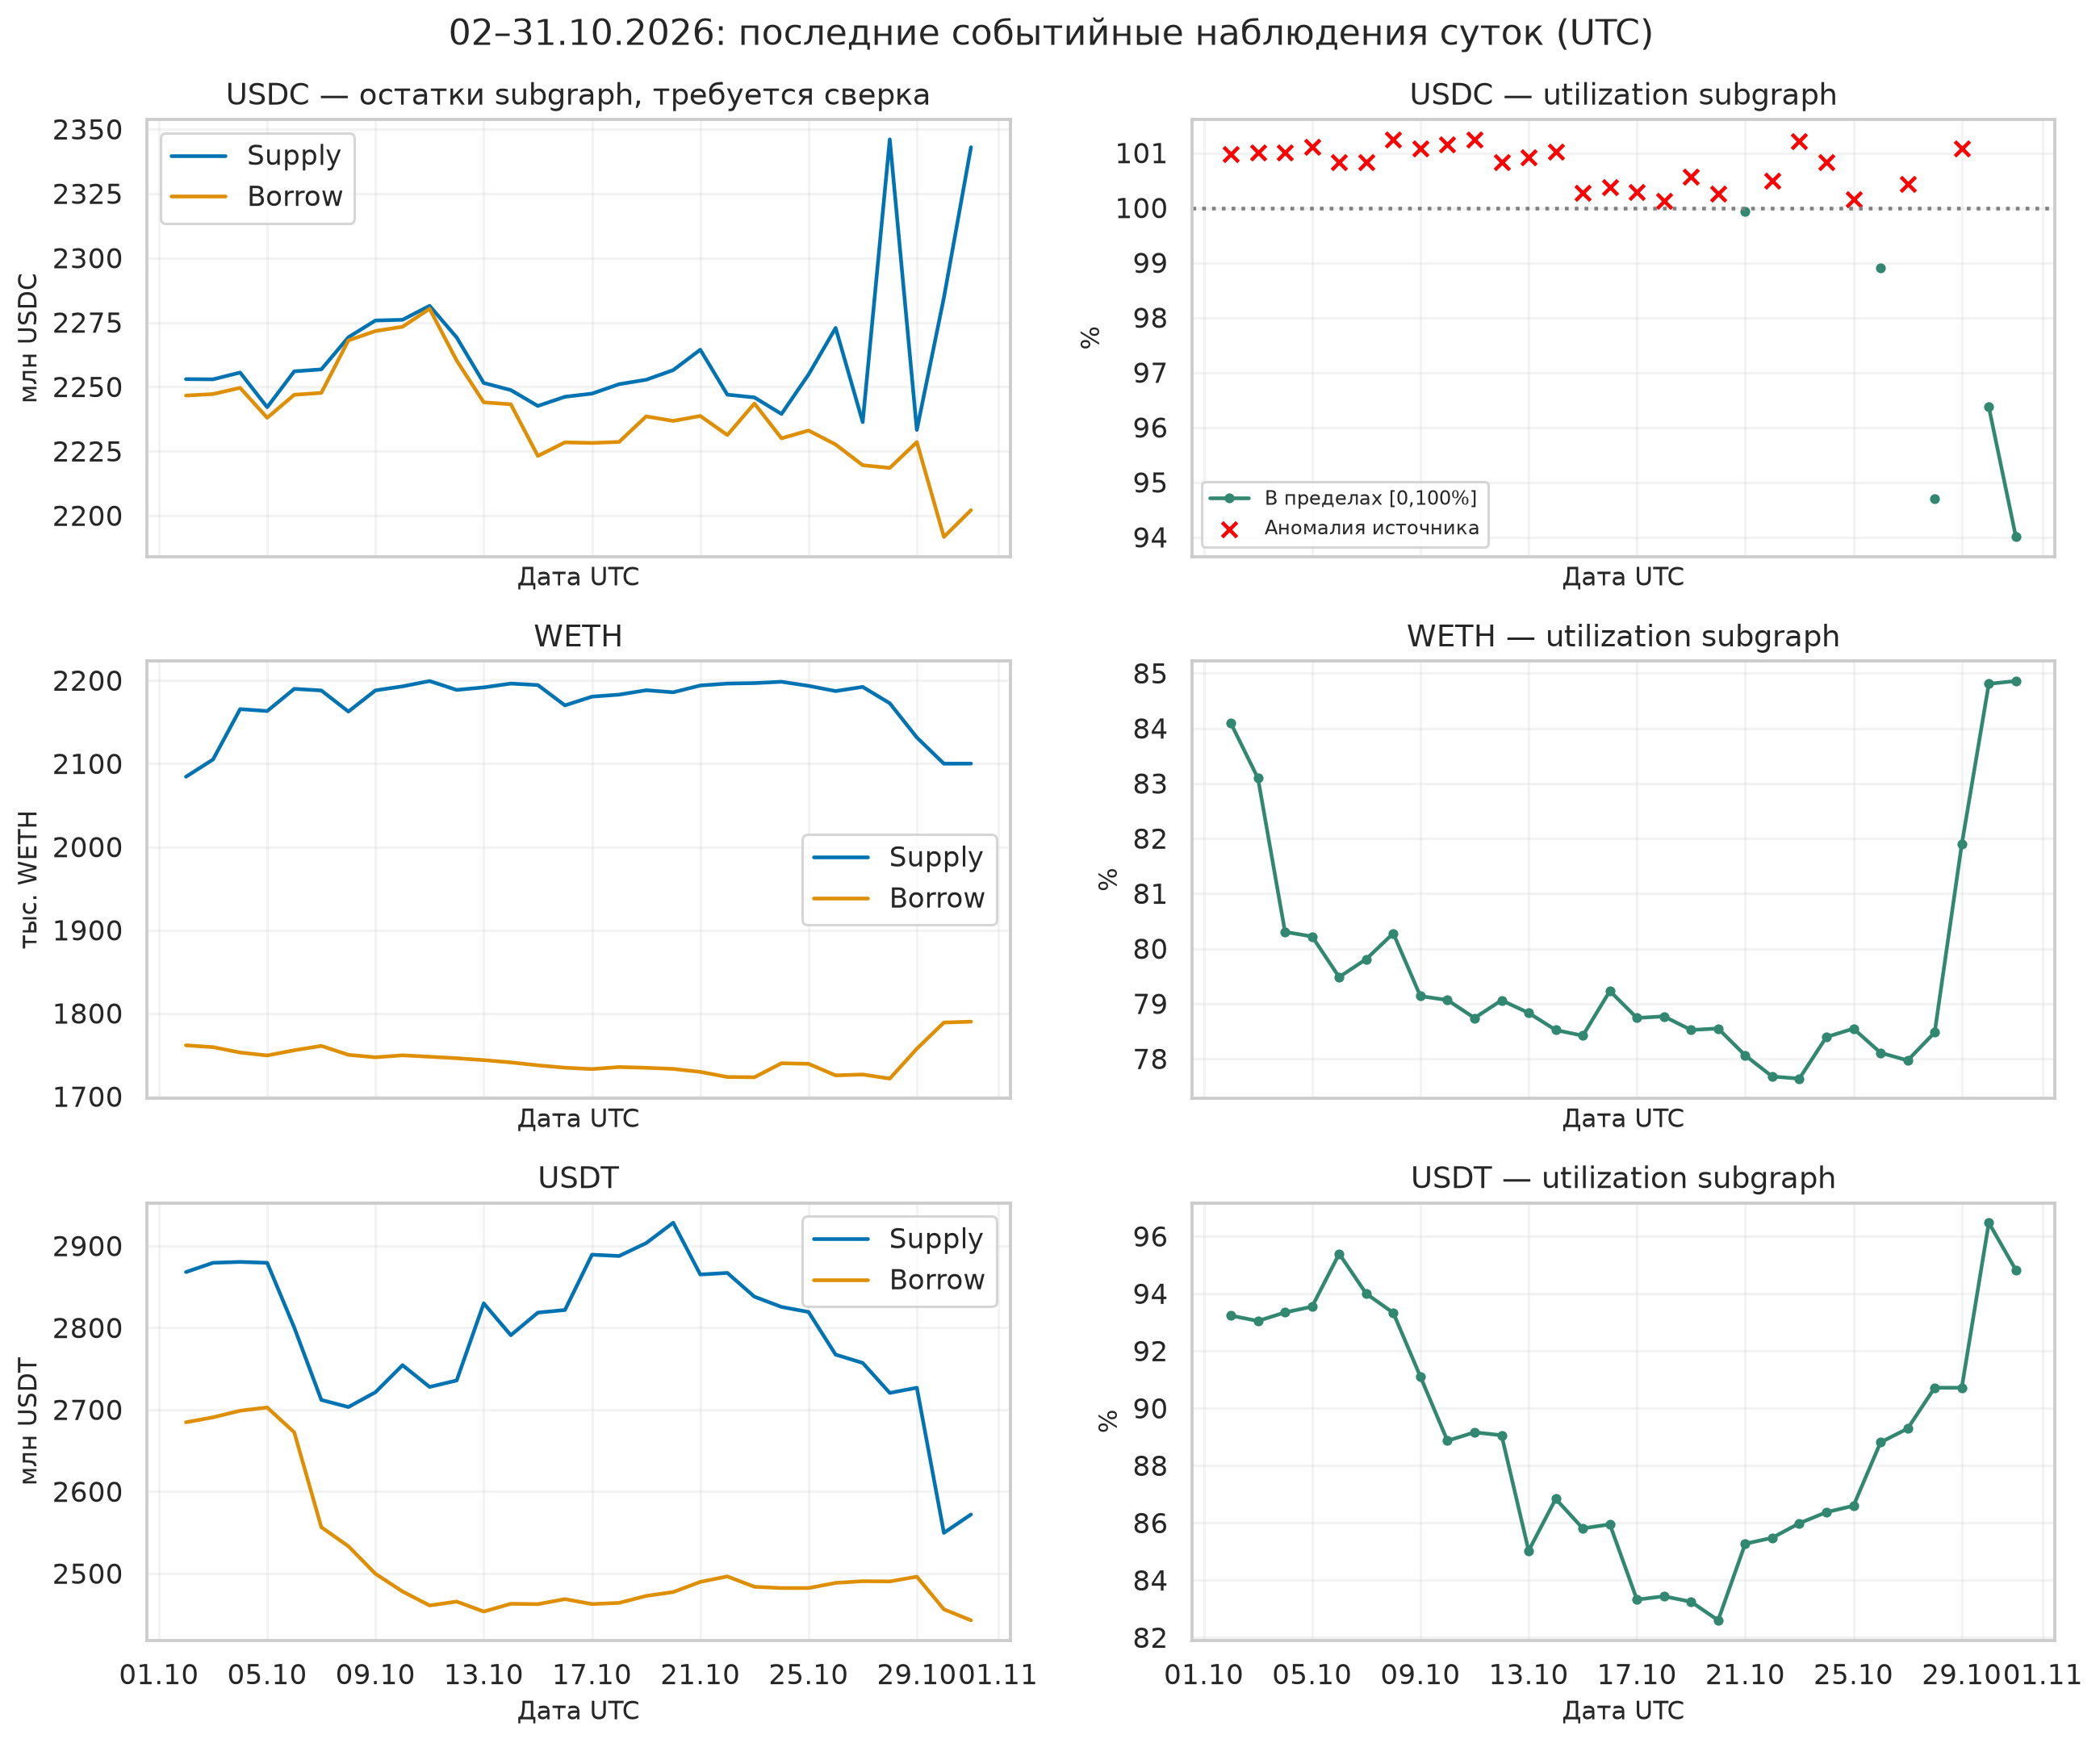

In [16]:
display(Image(filename=str(paths["11_lending_30d"])))

## Independent Quality Check

# Независимая проверка USDC перед финальной сборкой

Проверены последние выбранные наблюдения за 02, 15 и 29 октября 2026 года: блоки **26108071, 26201363, 26301843**. Сеть Ethereum (chainId=1), Pool `0x87870Bca3F3fD6335C3F4ce8392D69350B4fA4E2`, USDC `0xA0b86991c6218b36c1d19D4a2e9Eb0cE3606eB48`.

| Дата | Available USDC: The Graph | USDC balanceOf(aToken): RPC |
| --- | ---: | ---: |
| 02.10.2026 | −18 140 439.846182 | 6 325 453.553238 |
| 15.10.2026 | −5 132 314.052166 | 19 333 582.568548 |
| 29.10.2026 | −19 908 664.961866 | 4 561 238.131511 |

Исторические `eth_call` выполнены через Ethereum RPC. Адрес aToken получен из `Pool.getReserveData(USDC)` на каждом блоке и совпал с официальным address book: `0x98C23E9d8f34FEFb1B7BD6a91B7FF122F4e16F5c`. Проверены `USDC.decimals()=6`, `USDC.balanceOf(aToken)`, `aToken.totalSupply()`, `variableDebtToken.totalSupply()` и `Pool.getVirtualUnderlyingBalance(USDC)`. Времена блоков совпали с timestamp выбранных событий. Сохранены block hash, calldata и ответы RPC.

Дополнительный запрос The Graph к **состоянию резерва на тех же блоках** подтвердил те же отрицательные availableLiquidity. 

Для выбранных точек источник аномалии локализован в данных subgraph.

Исходные значения и все **25 quality_invalid** сохранены. Месячная utilization USDC исключена из экономических выводов; snapshot 31.10 не заменён.


Методика официального [AaveProtocolDataProvider](https://github.com/aave/aave-v3-origin/blob/main/src/contracts/helpers/AaveProtocolDataProvider.sol): supply и debt читаются из totalSupply соответствующих токенов; virtual underlying balance — отдельное поле Pool. RPC-состояние — конец блока; The Graph reserve запрошен на том же номере блока, что устраняет различие между событием и концом блока для проверяемого отрицательного поля.

In [17]:
display(independent)
display(daily.groupby("symbol").quality_invalid.sum().rename("Аномальные даты"))

,date,block,Graph available USDC,RPC cash USDC
0,20261002,26108071,-1.814044e+07,6.325454e+06
1,20261015,26201363,-5.132314e+06,1.933358e+07
2,20261029,26301843,-1.990866e+07,4.561238e+06


symbol
USDC    25
USDT     0
WETH     0
Name: Аномальные даты, dtype: int64

## Sources / Reproducibility

[DeFiLlama методика](https://docs.llama.fi/list-your-project/other-dashboards) · [Aave subgraphs / APY](https://github.com/aave/protocol-subgraphs) · [Aave utilization](https://github.com/aave/protocol-subgraphs/blob/main/src/helpers/reserve-logic.ts) · [Aave DataProvider](https://github.com/aave/aave-v3-origin/blob/main/src/contracts/helpers/AaveProtocolDataProvider.sol) · [CoinGecko API](https://docs.coingecko.com/) · [Etherscan V2](https://docs.etherscan.io/). Рабочая среда исходного исследования: Python 3.13; версии библиотек текущего запуска выводятся ниже. Для обновления источников нужны новые запросы, квоты и для The Graph/Etherscan API-ключи; этот notebook воспроизводит зафиксированный срез.

In [18]:
import matplotlib, seaborn, platform
print({"python":platform.python_version(),"pandas":pd.__version__,"numpy":np.__version__,"matplotlib":matplotlib.__version__,"seaborn":seaborn.__version__})
artifact={"summary":summary,"correlations":robust.to_dict("records"),"independent":independent.to_dict("records"),"figures":{k:str(v.name) for k,v in paths.items()}}
(EDA_DIR/"results.json").write_text(json.dumps(artifact,ensure_ascii=False,indent=2),encoding="utf-8")
assert len(paths)==11 and len(events)==3260
print("Проверено: 11 графиков, совпадение двух наборов событий, 25 сохранённых флагов USDC; расчёт без API и файлов проекта.")

{'python': '3.13.5', 'pandas': '2.3.3', 'numpy': '2.5.5', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}
Проверено: 11 графиков, совпадение двух наборов событий, 25 сохранённых флагов USDC; расчёт без API и файлов проекта.
